# Clasificación de imágenes de MRI cerebral con Redes Neuronales Convolucionales

**Microproyecto — Deep Learning (MAIA)**

## Introducción

**Contexto y relevancia.** Los tumores del sistema nervioso central forman un grupo heterogéneo. Su tipo histológico y molecular determina el pronóstico y el tratamiento [1]. La resonancia magnética (MRI) es la modalidad de imagen principal para detectarlos y caracterizarlos, pero interpretarla requiere tiempo y experiencia, y está sujeta a variabilidad entre evaluadores. Una herramienta automática de clasificación puede priorizar estudios, dar una segunda opinión consistente y apoyar a radiólogos en formación.

**Problema.** Dado un corte 2D extraído de un volumen de MRI cerebral, asignarle una de cuatro clases: `glioma`, `meningioma`, `pituitary` (adenoma hipofisario) o `healthy` (sin tumor). Trabajar con cortes individuales en vez del volumen completo reduce el costo computacional y convierte la tarea en clasificación de imágenes.

**Estado del arte.** Las CNN dominan la clasificación de imágenes desde que las arquitecturas profundas con kernels pequeños 3×3 [2], la normalización por lotes [3] y las conexiones residuales [4] permitieron entrenar redes profundas de forma estable. En tumores cerebrales, Cheng *et al.* [5] publicaron el conjunto de figshare (3 064 cortes T1 con contraste, 3 tipos de tumor). Badža y Barjaktarović [6] reportan 96,56 % de accuracy con una CNN propia sobre ese mismo conjunto. Sin embargo, Yagis *et al.* [7] muestran que en MRI cerebral una partición a nivel de corte, en lugar de sujeto, puede inflar el accuracy de test hasta en 55 puntos porcentuales, por lo que la forma de dividir los datos es tan importante como el modelo. Además, las CNN tienden a aprender "atajos" (señales espurias correlacionadas con la etiqueta) en lugar del concepto buscado [8].

**Objetivos.**
1. Construir un pipeline reproducible de carga, preprocesamiento y partición train/val/test **sin duplicados entre particiones**.
2. Diseñar y entrenar una CNN basada en bloques de convolución y max pooling que clasifique las 4 categorías.
3. Evaluar el modelo con métricas adecuadas al contexto clínico, cuantificar su variabilidad y el efecto de la fuga de datos, e interpretar sus decisiones con Grad-CAM [9].

**Qué se realiza.** Se entrena desde cero una CNN compacta de 4 bloques (~0,3 M parámetros) sobre imágenes de 128×128 en escala de grises. Se usa una partición por grupos de (casi-)duplicados y se compara con la partición aleatoria. También se implementa, como alternativa, el fine-tuning de ResNet-18 preentrenada [4].

**Dataset.** [Brain Tumor (MRI Scans) — Kaggle](https://www.kaggle.com/datasets/rm1000/brain-tumor-mri-scans): 7 023 imágenes, una carpeta por clase en `data/raw/`. Su tamaño y sus clases coinciden con la compilación de Chaki [10], que une figshare [5] y SARTAJ (tumores) con Br35H (clase sin tumor).

| # | Actividad del enunciado | Sección |
|---|-----------|---------|
| 1 | Pipeline para cargar las imágenes y dividirlas en entrenamiento y prueba | Secciones 1 a 3 |
| 2 | Arquitectura CNN (bloques convolución + max pooling, o fine-tuning de una red existente) | Secciones 4 a 7 |

**Flujo:** Configuración → Análisis exploratorio → Partición por grupos → Pipeline → Arquitectura → Entrenamiento → Evaluación → Transfer learning (opcional) → Experimentos comparativos → Discusión → Referencias.

> Todas las cifras provienen de la ejecución de este notebook (salidas de cada celda). La discusión de la Sección 8 se escribió leyendo esas salidas.

## 0. Configuración y reproducibilidad

In [1]:
import os, time, random, hashlib, json, platform, itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision.transforms import v2 as T

from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, confusion_matrix, roc_auc_score)

CONFIG = dict(
    seed=42,
    img_size=128,            # resolución de entrada (ver justificación en la Sección 3)
    batch_size=64,
    epochs=30,               # máximo; se usa early stopping
    patience=8,              # épocas sin mejora en F1-macro de validación
    lr=1e-3,
    weight_decay=1e-4,
    label_smoothing=0.05,
    channels=(16, 32, 64, 128),
    dropout=0.3,
    split_file="data/splits/split_grupos.csv",
)
CLASSES = ["glioma", "meningioma", "pituitary", "healthy"]   # orden = columna `label` de los CSV
# Raíz del repositorio: funciona desde notebooks/ o desde la raíz (sube hasta encontrar data/raw y data/splits)
ROOT = Path.cwd().resolve()
while not ((ROOT / "data" / "raw").exists() and (ROOT / "data" / "splits").exists()) and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / "data" / "raw").exists(), "No se encontró data/raw: ejecute el notebook dentro del repositorio."
MODELS = ROOT / "outputs" / "models"        # pesos, historiales y resultados de esta solución
REPORT_FIGS = ROOT / "report" / "figs"      # figuras que usa el informe (report/main.tex)
for d in [MODELS, REPORT_FIGS, ROOT / "data" / "cache"]:
    d.mkdir(parents=True, exist_ok=True)
print("Raíz del proyecto:", ROOT.name, "| modelos en", MODELS.relative_to(ROOT), "| figuras del informe en", REPORT_FIGS.relative_to(ROOT))

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_seed(CONFIG["seed"])

DEVICE = ("cuda" if torch.cuda.is_available()
          else "mps" if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available()
          else "cpu")
print(f"Python {platform.python_version()} | torch {torch.__version__} | torchvision {torchvision.__version__}")
print(f"Dispositivo: {DEVICE} | hilos CPU: {torch.get_num_threads()}")
print(json.dumps(CONFIG, indent=1))

Raíz del proyecto: brain-tumor-mri-cnn | modelos en outputs/models | figuras del informe en report/figs
Python 3.13.16 | torch 2.14.1+cu130 | torchvision 0.29.1+cu130
Dispositivo: cpu | hilos CPU: 2
{
 "seed": 42,
 "img_size": 128,
 "batch_size": 64,
 "epochs": 30,
 "patience": 8,
 "lr": 0.001,
 "weight_decay": 0.0001,
 "label_smoothing": 0.05,
 "channels": [
  16,
  32,
  64,
  128
 ],
 "dropout": 0.3,
 "split_file": "data/splits/split_grupos.csv"
}


## 1. Análisis exploratorio

`data/splits/inventario.csv` contiene una fila por imagen con su clase, tamaño, modo de color, intensidad media, un hash exacto (`md5`) y un hash perceptual (`dhash`). La columna `grupo` agrupa imágenes **idénticas o casi idénticas**, lo cual es clave para evitar fuga de datos (Sección 2). El criterio de agrupamiento se reconstruye y verifica en la Sección 1b.

Imágenes: 7023 | clases: 4


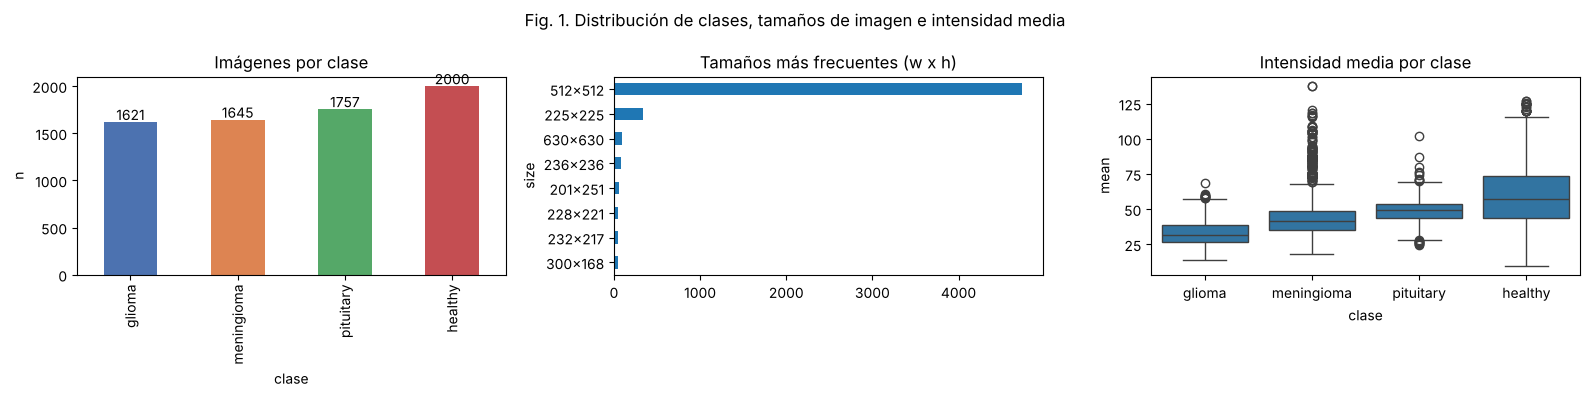

Tamaños distintos: 387 | 512x512: 4742 (67.5%)
Relación de aspecto != 1: 1608 imágenes
Modo de color: {'RGB': 7023}
Imágenes con duplicado exacto (md5): 726 | md5 repetidos en >1 clase: 0
Grupos (casi-)duplicados: 5835 para 7023 imágenes | grupos con >1 imagen: 581 | grupos con >1 clase: 0


In [2]:
inv = pd.read_csv(ROOT / "data/splits/inventario.csv", dtype={"dhash": str})
assert inv["path"].map(lambda p: (ROOT / p).exists()).all(), "Faltan imágenes en data/raw"
print(f"Imágenes: {len(inv)} | clases: {inv['clase'].nunique()}")
assert (inv.groupby("clase")["label"].first().sort_values().index.tolist() == CLASSES)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
inv["clase"].value_counts().reindex(CLASSES).plot.bar(ax=axes[0], color=sns.color_palette("deep", 4))
axes[0].set_title("Imágenes por clase"); axes[0].set_ylabel("n")
for i, v in enumerate(inv["clase"].value_counts().reindex(CLASSES)):
    axes[0].text(i, v + 20, str(v), ha="center")
sizes = inv.assign(size=inv["w"].astype(str) + "x" + inv["h"].astype(str))["size"].value_counts()
sizes.head(8).plot.barh(ax=axes[1]); axes[1].set_title("Tamaños más frecuentes (w x h)"); axes[1].invert_yaxis()
sns.boxplot(data=inv, x="clase", y="mean", order=CLASSES, ax=axes[2]); axes[2].set_title("Intensidad media por clase")
plt.suptitle("Fig. 1. Distribución de clases, tamaños de imagen e intensidad media"); plt.tight_layout(); plt.show()

print(f"Tamaños distintos: {sizes.size} | 512x512: {sizes.get('512x512', 0)} ({sizes.get('512x512', 0)/len(inv):.1%})")
print(f"Relación de aspecto != 1: {(inv['w'] != inv['h']).sum()} imágenes")
print(f"Modo de color: {inv['mode'].value_counts().to_dict()}")
dup = inv["md5"].duplicated(keep=False)
print(f"Imágenes con duplicado exacto (md5): {dup.sum()} | md5 repetidos en >1 clase: "
      f"{(inv[dup].groupby('md5')['clase'].nunique() > 1).sum()}")
print(f"Grupos (casi-)duplicados: {inv['grupo'].nunique()} para {len(inv)} imágenes | "
      f"grupos con >1 imagen: {(inv['grupo'].value_counts() > 1).sum()} | grupos con >1 clase: "
      f"{(inv.groupby('grupo')['clase'].nunique() > 1).sum()}")

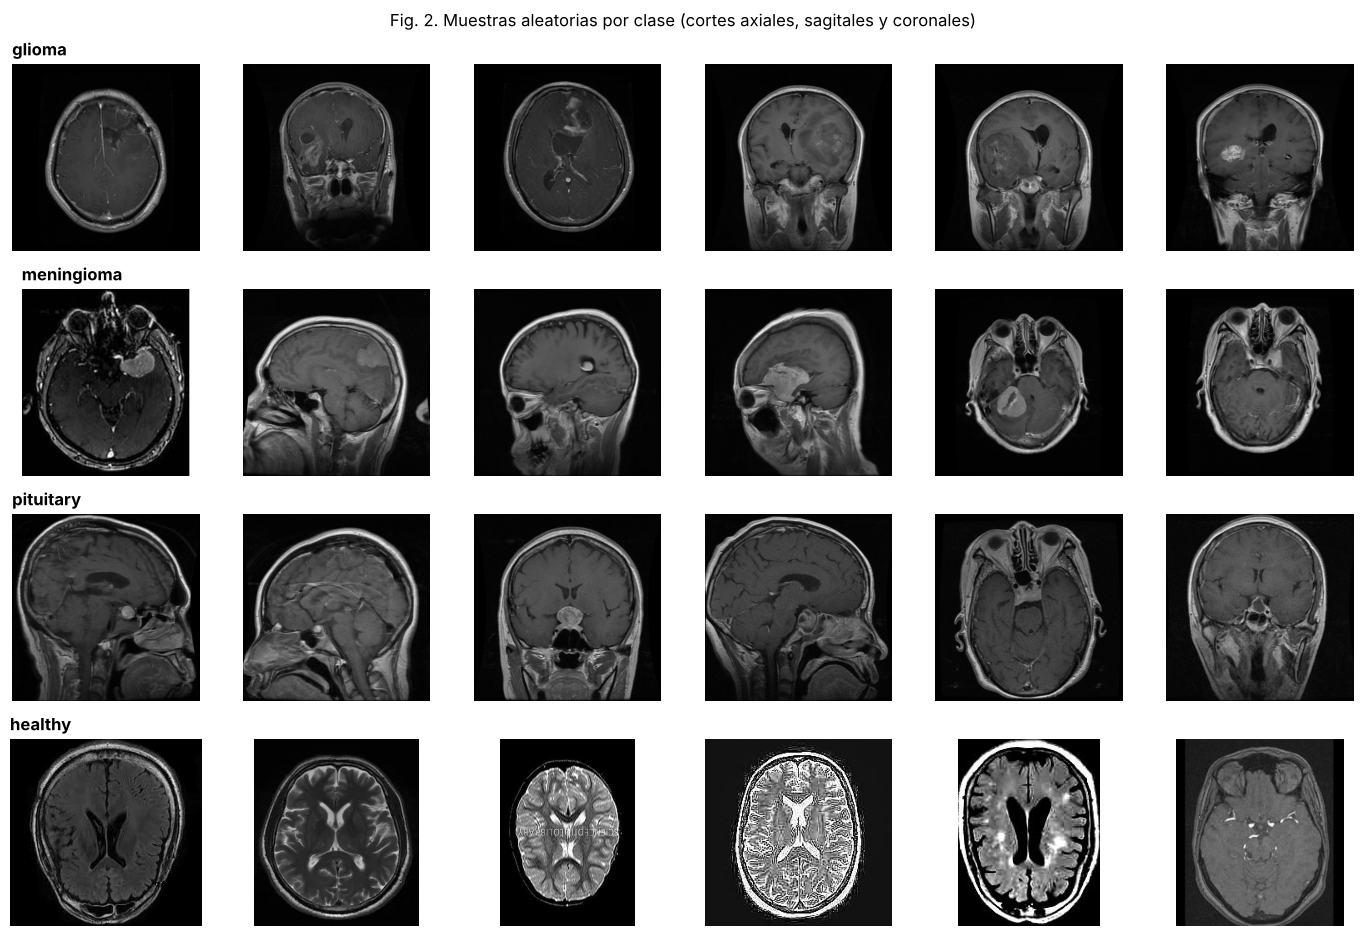

Diferencia media |R-G|,|G-B| en 200 imágenes: 0.006 niveles de gris (máx. por imagen 1.138)


In [3]:
rng = np.random.default_rng(CONFIG["seed"])
fig, axes = plt.subplots(4, 6, figsize=(14, 9.5))
for r, c in enumerate(CLASSES):
    paths = inv.loc[inv["clase"] == c, "path"].to_numpy()
    for k, p in enumerate(rng.choice(paths, 6, replace=False)):
        ax = axes[r, k]; ax.imshow(Image.open(ROOT / p).convert("L"), cmap="gray"); ax.axis("off")
        if k == 0: ax.set_title(c, loc="left", fontsize=12, fontweight="bold")
plt.suptitle("Fig. 2. Muestras aleatorias por clase (cortes axiales, sagitales y coronales)"); plt.tight_layout(); plt.show()

# ¿Los canales RGB contienen información distinta? (MRI es intrínsecamente monocanal)
diffs = []
for p in rng.choice(inv["path"].to_numpy(), 200, replace=False):
    a = np.asarray(Image.open(ROOT / p).convert("RGB"), dtype=np.int16)
    diffs.append((np.abs(a[..., 0] - a[..., 1]).mean() + np.abs(a[..., 1] - a[..., 2]).mean()) / 2)
print(f"Diferencia media |R-G|,|G-B| en 200 imágenes: {np.mean(diffs):.3f} niveles de gris (máx. por imagen {np.max(diffs):.3f})")

**Observaciones**
- Las clases están razonablemente balanceadas (≈1 600–2 000 por clase), por lo que no se usan pesos de clase; aun así se reporta F1-macro y *balanced accuracy*.
- Hay tamaños y relaciones de aspecto heterogéneos → el pipeline debe llevar todo a un tamaño fijo **sin deformar** la anatomía.
- Las imágenes vienen como RGB pero son, en la práctica, escala de grises (diferencias entre canales despreciables, propias de la compresión JPEG) → se usa **1 canal** (reduce cómputo ×3 en la primera capa sin perder información).
- Existen duplicados exactos y casi-duplicados: si caen en particiones distintas, el modelo se evalúa con imágenes que ya "vio".

### 1b. Duplicados, redundancia por clase y diferencias de adquisición

**Criterio de agrupamiento.** Los grupos de `inventario.csv` se generaron con dos reglas, unidas con *union-find* (componentes conexas):
1. **Copia exacta:** mismo hash MD5.
2. **Casi-duplicado:** mismo *difference hash* (dHash de 64 bits) **y** correlación de Pearson ≥ 0,95 entre miniaturas de 128×128 en gris (z-score). Esta regla captura copias reescaladas o con el contraste modificado.

La celda siguiente **reconstruye los grupos con ese criterio y comprueba que coinciden** con la columna `grupo`. Como los candidatos se buscan por dHash idéntico, el número de copias encontrado es un límite inferior.

In [4]:
DUP_CORR = 0.95
def thumb_z(path):
    a = np.asarray(Image.open(ROOT / path).convert("L").resize((128, 128), Image.BILINEAR), dtype=np.float32).ravel()
    return (a - a.mean()) / (a.std() + 1e-6)

parent = list(range(len(inv)))
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]; x = parent[x]
    return x
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb: parent[rb] = ra

for _, g in inv.groupby("md5"):                      # 1) copias exactas
    for j in g.index[1:]: union(g.index[0], j)
pares, cache_z = [], {}
for _, g in inv.groupby("dhash"):                    # 2) casi-duplicados
    if len(g) < 2: continue
    for a, b in itertools.combinations(g.itertuples(), 2):
        if a.md5 == b.md5: continue
        za = cache_z.setdefault(a.Index, thumb_z(a.path)); zb = cache_z.setdefault(b.Index, thumb_z(b.path))
        r = float(np.dot(za, zb) / za.size)
        pares.append((a.clase, b.clase, r))
        if r >= DUP_CORR: union(a.Index, b.Index)
grupo_rec = np.array([find(i) for i in range(len(inv))])

# ¿La partición reconstruida es la misma que la columna `grupo`? (misma relación de equivalencia)
same = (pd.crosstab(grupo_rec, inv["grupo"]).astype(bool).sum(axis=1).max() == 1 and
        pd.crosstab(inv["grupo"], grupo_rec).astype(bool).sum(axis=1).max() == 1)
P = pd.DataFrame(pares, columns=["c1", "c2", "corr"])
print(f"Grupos reconstruidos: {len(set(grupo_rec))} | coinciden con inventario.csv: {same}")
print(f"Pares candidatos (mismo dHash, distinto MD5): {len(P)} | sobre el umbral: {(P['corr'] >= DUP_CORR).sum()}")
print(f"Pares candidatos entre clases distintas: {(P.c1 != P.c2).sum()} | correlación máxima entre clases: "
      f"{P.loc[P.c1 != P.c2, 'corr'].max():.3f} | sobre el umbral: {((P.c1 != P.c2) & (P['corr'] >= DUP_CORR)).sum()}")
print(f"Grupos con imágenes de más de una clase: {(inv.groupby('grupo')['clase'].nunique() > 1).sum()} | "
      f"tamaño del grupo más grande: {inv['grupo'].value_counts().max()}")

Grupos reconstruidos: 5835 | coinciden con inventario.csv: True
Pares candidatos (mismo dHash, distinto MD5): 3292 | sobre el umbral: 2311
Pares candidatos entre clases distintas: 40 | correlación máxima entre clases: 0.795 | sobre el umbral: 0
Grupos con imágenes de más de una clase: 0 | tamaño del grupo más grande: 26


Tabla 0. Redundancia y características de adquisición por clase


,imagenes,cortes_unicos,redundantes,% redundante,ancho_mediana,alto_mediana,% 512x512,% no cuadradas,intensidad_media
clase,,,,,,,,,
glioma,1621,1618,3,0.2,512.0,512.0,100.0,0.0,32.95
meningioma,1645,1525,120,7.3,512.0,512.0,84.3,13.4,45.15
pituitary,1757,1735,22,1.3,512.0,512.0,97.6,0.4,48.97
healthy,2000,957,1043,52.2,232.0,243.0,1.0,69.0,60.40


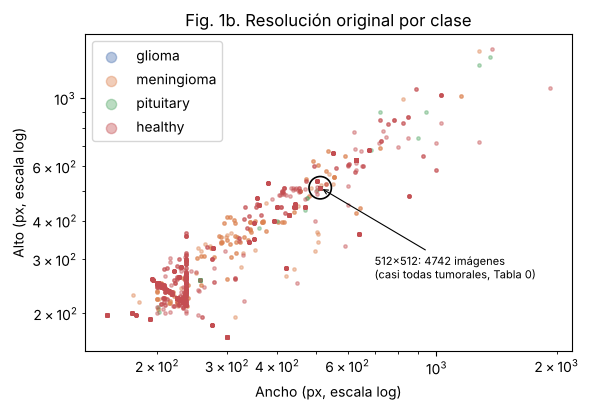

In [5]:
# Redundancia por clase y diferencias de adquisición
red = inv.groupby("clase").agg(imagenes=("path", "size"), cortes_unicos=("grupo", "nunique"),
                               ancho_mediana=("w", "median"), alto_mediana=("h", "median"),
                               intensidad_media=("mean", "mean")).reindex(CLASSES)
red["redundantes"] = red["imagenes"] - red["cortes_unicos"]
red["% redundante"] = (100 * red["redundantes"] / red["imagenes"]).round(1)
red["% no cuadradas"] = (100 * inv.assign(nc=inv.w != inv.h).groupby("clase")["nc"].mean()).reindex(CLASSES).round(1)
red["% 512x512"] = (100 * inv.assign(s=(inv.w == 512) & (inv.h == 512)).groupby("clase")["s"].mean()).reindex(CLASSES).round(1)
print("Tabla 0. Redundancia y características de adquisición por clase")
display(red[["imagenes", "cortes_unicos", "redundantes", "% redundante", "ancho_mediana", "alto_mediana",
             "% 512x512", "% no cuadradas", "intensidad_media"]].round(2))

fig, ax = plt.subplots(figsize=(6, 4.2))
for c, col in zip(CLASSES, sns.color_palette("deep", 4)):
    sub = inv[inv.clase == c]
    ax.scatter(sub.w, sub.h, s=6, alpha=0.4, label=c, color=col)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("Ancho (px, escala log)"); ax.set_ylabel("Alto (px, escala log)")
n512 = int(((inv.w == 512) & (inv.h == 512)).sum())
ax.scatter([512], [512], s=260, facecolors="none", edgecolors="k", lw=1.2)
ax.annotate(f"512×512: {n512} imágenes\n(casi todas tumorales, Tabla 0)", xy=(512, 512), xytext=(700, 260),
            fontsize=8, arrowprops=dict(arrowstyle="->", lw=0.8))
ax.legend(markerscale=3); ax.set_title("Fig. 1b. Resolución original por clase")
plt.tight_layout(); plt.show()

**Hallazgos de la Sección 1b**
- **Redundancia muy desigual:** la clase `healthy` tiene más de la mitad de sus imágenes repetidas (copias exactas o reescaladas del mismo corte). En cortes únicos, el balance real de clases es distinto del aparente. Por eso la partición debe hacerse por grupos (Sección 2).
- **Diferencias de adquisición:** la clase `healthy` tiene una resolución típica mucho menor que las clases tumorales (que son mayoritariamente de 512×512) y una intensidad media mayor. Esto coincide con su procedencia de otra fuente (Br35H [10]) y abre la posibilidad de que la red aprenda **atajos** (resolución, intensidad, secuencia) en lugar de la patología [8]. Se discute en la Sección 8.

## 2. Partición train / validación / test sin duplicados entre particiones

Se dispone de dos particiones versionadas (70/15/15, estratificadas por clase):
- `split_aleatorio.csv`: partición aleatoria por imagen.
- `split_grupos.csv`: partición por **grupo** de (casi-)duplicados — todas las imágenes de un grupo van a la misma partición.

Se verifica cuantitativamente cuál evita la fuga y se usa esa para todo el proyecto. El conjunto de **test sólo se usa una vez**, al final (Sección 6); la selección de modelo e hiperparámetros se hace con validación.

In [6]:
def leakage_report(split):
    g = split.groupby("grupo")["split"].nunique()
    md5_split = split.merge(inv[["path", "md5"]], on="path").groupby("md5")["split"].nunique()
    test_groups = set(split.loc[split.split == "test", "grupo"])
    train_groups = set(split.loc[split.split == "train", "grupo"])
    n_test_leak = split[(split.split == "test") & split.grupo.isin(train_groups)].shape[0]
    return {"grupos en >1 partición": int((g > 1).sum()),
            "md5 en >1 partición": int((md5_split > 1).sum()),
            "imágenes de test con (casi-)duplicado en train": n_test_leak}

splits = {name: pd.read_csv(ROOT / f"data/splits/split_{name}.csv") for name in ["aleatorio", "grupos"]}
display(pd.DataFrame({k: leakage_report(v) for k, v in splits.items()}))

split = pd.read_csv(ROOT / CONFIG["split_file"])
assert set(split["path"]) == set(inv["path"]) and len(split) == len(inv)
assert leakage_report(split)["grupos en >1 partición"] == 0
tab = pd.crosstab(split["clase"], split["split"]).reindex(CLASSES)[["train", "val", "test"]]
tab.loc["total"] = tab.sum()
display(tab.assign(**{"% train": (tab["train"] / tab.sum(axis=1)).round(3)}))

# Verificación adicional: imágenes de val/test con dHash IDÉNTICO a alguna de train (no capturadas por `grupo`)
dh = split.merge(inv[["path", "dhash"]], on="path")
train_dh = dh[dh["split"] == "train"].groupby("dhash")["path"].apply(list)
def _small(p):
    return np.asarray(ImageOps.pad(Image.open(ROOT / p).convert("L"), (96, 96), color=0), dtype=np.float32)
for s in ["val", "test"]:
    r = dh[(dh["split"] == s) & dh["dhash"].isin(train_dh.index)]
    print(f"{s}: {len(r)} de {(dh['split'] == s).sum()} imágenes ({len(r) / (dh['split'] == s).sum():.1%}) "
          f"comparten dHash idéntico con alguna imagen de train")
    if s == "test":
        RESIDUAL_TEST = set(r["path"])
        mae = np.array([min(np.abs(_small(p) - _small(q)).mean() for q in train_dh[h]) for p, h in zip(r["path"], r["dhash"])])
        print(f"   diferencia media por píxel con su par más parecido en train (0-255): "
              f"mín {mae.min():.1f}, mediana {np.median(mae):.1f}, máx {mae.max():.1f} -> ninguna es copia exacta")
        rmax = np.array([max(float(np.dot(thumb_z(p), thumb_z(q)) / 128 ** 2) for q in train_dh[h])
                         for p, h in zip(r["path"], r["dhash"])])
        print(f"   correlación de Pearson con su par más parecido en train: máx {rmax.max():.3f} "
              f"(< {DUP_CORR} -> por eso el criterio de la Sección 1b no las agrupó) | mediana {np.median(rmax):.3f}")

,aleatorio,grupos
grupos en >1 partición,324,0
md5 en >1 partición,144,0
imágenes de test con (casi-)duplicado en train,220,0


split,train,val,test,% train
clase,,,,
glioma,1158,232,231,0.714
meningioma,1175,235,235,0.714
pituitary,1255,251,251,0.714
healthy,1428,286,286,0.714
total,5016,1004,1003,0.714


val: 41 de 1004 imágenes (4.1%) comparten dHash idéntico con alguna imagen de train
test: 55 de 1003 imágenes (5.5%) comparten dHash idéntico con alguna imagen de train


   diferencia media por píxel con su par más parecido en train (0-255): mín 5.7, mediana 15.0, máx 43.9 -> ninguna es copia exacta


   correlación de Pearson con su par más parecido en train: máx 0.942 (< 0.95 -> por eso el criterio de la Sección 1b no las agrupó) | mediana 0.673


La partición aleatoria deja imágenes de test con un (casi-)duplicado en train, lo que **inflaría** las métricas de test, un fenómeno documentado en MRI cerebral [7]. Por eso se usa `split_grupos.csv`: 0 grupos y 0 duplicados exactos compartidos entre particiones. El efecto se cuantifica en la Sección 7b.

**Fuga residual.** Aun con la partición por grupos, un 5,5 % de las imágenes de test comparte un dHash idéntico con alguna imagen de train. No son copias: su correlación con el par más parecido queda por debajo del umbral de 0,95 de la Sección 1b, y por eso no se agruparon. Visualmente corresponden a cortes muy parecidos, probablemente del mismo paciente. Como el dataset no tiene identificador de paciente, la partición **elimina duplicados pero no garantiza la separación por paciente**. Su efecto sobre las métricas se mide en la Sección 7b.

## 3. Pipeline de carga y preprocesamiento

**Decisiones**
1. **Escala de grises (1 canal)**: los tres canales son prácticamente idénticos (Sección 1).
2. **Pad-to-square + resize a 128×128**: `ImageOps.pad` conserva la relación de aspecto rellenando con negro (el fondo natural de la MRI) en lugar de estirar la imagen. 128 px mantienen la forma y localización de las lesiones y hacen el entrenamiento viable en CPU (el tamaño se cambia en `CONFIG["img_size"]`).
3. **Caché en memoria / disco**: las 7 023 imágenes a 128×128 ocupan ≈115 MB en `uint8`; se decodifican una sola vez y se guardan en `data/cache/`.
4. **Normalización** con media y desviación estándar calculadas **sólo en train**.
5. **Aumentación de datos (sólo train)**: volteo horizontal (el cerebro es aproximadamente simétrico), rotación ±10°, traslación ±5 %, escala 0.9–1.1 y variaciones leves de brillo/contraste. Simula variaciones de adquisición/posicionamiento sin crear anatomías imposibles (no se usa volteo vertical). La variación de **brillo y contraste** busca además que la red no dependa del nivel de intensidad, que difiere entre la clase `healthy` y las tumorales (Tabla 0, Sección 1b).

In [7]:
def load_image(path, size):
    img = Image.open(ROOT / path).convert("L")
    img = ImageOps.pad(img, (size, size), method=Image.BILINEAR, color=0)
    return np.asarray(img, dtype=np.uint8)

def build_cache(paths, size):
    key = hashlib.md5(("|".join(paths) + str(size)).encode()).hexdigest()[:10]
    f = ROOT / "data" / "cache" / f"gray_{size}_{key}.npy"
    if f.exists():
        print(f"Cargando caché {f.name}")
        return np.load(f)
    t0 = time.time()
    X = np.stack([load_image(p, size) for p in paths])
    np.save(f, X)
    print(f"Caché creada {f.name} en {time.time() - t0:.1f}s")
    return X

S = CONFIG["img_size"]
X_all = build_cache(split["path"].tolist(), S)              # (N, S, S) uint8, mismo orden que `split`
y_all = split["label"].to_numpy()
idx = {s: np.where(split["split"].to_numpy() == s)[0] for s in ["train", "val", "test"]}
print({k: len(v) for k, v in idx.items()}, "| X:", X_all.shape, X_all.dtype, f"{X_all.nbytes/1e6:.0f} MB")

MEAN = X_all[idx["train"]].mean() / 255.0
STD = X_all[idx["train"]].std() / 255.0
print(f"Normalización (sólo train): mean={MEAN:.4f}, std={STD:.4f}")

Cargando caché gray_128_08a47af315.npy
{'train': 5016, 'val': 1004, 'test': 1003} | X: (7023, 128, 128) uint8 115 MB


Normalización (sólo train): mean=0.1789, std=0.1942


Batch: (64, 1, 128, 128) torch.float32 | media=-0.002, std=0.999


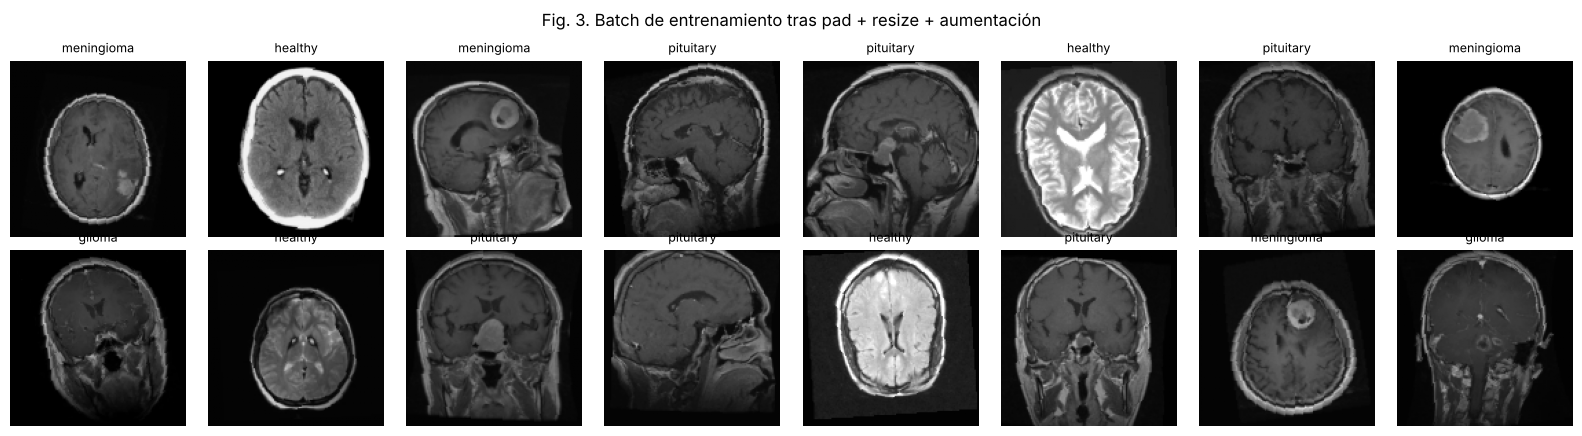

In [8]:
class MRIDataset(Dataset):
    def __init__(self, X, y, train, n_channels=1, mean=MEAN, std=STD):
        self.X = torch.from_numpy(X).unsqueeze(1)          # (N,1,S,S) uint8
        self.y = torch.from_numpy(y).long()
        self.n_channels, self.mean, self.std = n_channels, mean, std
        self.aug = T.Compose([
            T.RandomHorizontalFlip(),
            T.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),
            T.ColorJitter(brightness=0.15, contrast=0.15),
        ]) if train else None

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        x = self.X[i]
        if self.aug is not None:
            x = self.aug(x)
        x = x.float().div(255.0)
        x = (x - self.mean) / self.std
        if self.n_channels == 3:
            x = x.expand(3, -1, -1)
        return x, self.y[i]

def make_loaders(n_channels=1, mean=MEAN, std=STD, bs=CONFIG["batch_size"]):
    g = torch.Generator().manual_seed(CONFIG["seed"])
    ds = {s: MRIDataset(X_all[idx[s]], y_all[idx[s]], train=(s == "train"),
                        n_channels=n_channels, mean=mean, std=std) for s in idx}
    return {s: DataLoader(ds[s], batch_size=bs, shuffle=(s == "train"), generator=g if s == "train" else None,
                          num_workers=0) for s in ds}

loaders = make_loaders()
xb, yb = next(iter(loaders["train"]))
print("Batch:", tuple(xb.shape), xb.dtype, f"| media={xb.mean():.3f}, std={xb.std():.3f}")

fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for ax, x, y in zip(axes.ravel(), xb[:16], yb[:16]):
    ax.imshow(x[0] * STD + MEAN, cmap="gray", vmin=0, vmax=1); ax.set_title(CLASSES[y], fontsize=9); ax.axis("off")
plt.suptitle("Fig. 3. Batch de entrenamiento tras pad + resize + aumentación"); plt.tight_layout(); plt.show()

## 4. Arquitectura CNN

Se diseña una CNN propia siguiendo la recomendación del enunciado (bloques de **convolución + max pooling**):

```
Entrada 1×128×128
 └─ 4 bloques: [Conv3×3 → BN → ReLU] ×2 → MaxPool2×2      canales 16 → 32 → 64 → 128
     (128 → 64 → 32 → 16 → 8 px)
 └─ Global Average Pooling → Dropout(0.3) → Linear(128 → 4)
```

**Justificación**
- Dos convoluciones 3×3 por bloque (estilo VGG [2]) amplían el campo receptivo (≈ 5×5 por bloque) con menos parámetros que un kernel grande; tras 4 bloques el campo receptivo cubre gran parte del cerebro, necesario para relacionar la lesión con su localización (p. ej. región selar → pituitary).
- **BatchNorm** [3] estabiliza y acelera el entrenamiento; **max pooling** da invarianza local y reduce resolución.
- **Global Average Pooling** [11] en lugar de capas densas grandes: reduce drásticamente los parámetros (~0.3 M) y el sobreajuste con ~4 900 imágenes de entrenamiento.
- Dropout antes del clasificador como regularización adicional.

In [9]:
def conv_block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        nn.MaxPool2d(2))

class MRICNN(nn.Module):
    def __init__(self, in_ch=1, channels=CONFIG["channels"], n_classes=4, dropout=CONFIG["dropout"]):
        super().__init__()
        layers, c = [], in_ch
        for c_out in channels:
            layers.append(conv_block(c, c_out)); c = c_out
        self.features = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(c, n_classes))

    def forward(self, x):
        return self.head(self.features(x))

set_seed(CONFIG["seed"])
model = MRICNN().to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"\nParámetros entrenables: {n_params:,}")
with torch.no_grad():
    x = torch.zeros(1, 1, S, S, device=DEVICE)
    for i, blk in enumerate(model.features):
        x = blk(x); print(f"Bloque {i+1}: {tuple(x.shape[1:])}")

MRICNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track

## 5. Entrenamiento

- **Pérdida**: entropía cruzada con *label smoothing* 0.05 [12] (mejora la calibración y evita sobreconfianza).
- **Optimizador**: AdamW [13] (lr 1e-3, weight decay 1e-4, batch 64) con *cosine annealing* [14] sobre 30 épocas máximas.
- **Selección del modelo**: se guarda el checkpoint con mejor **F1-macro en validación**; *early stopping* con paciencia 8.
- Se registran pérdida, accuracy y F1-macro de train y validación en cada época.

In [10]:
def run_epoch(model, loader, criterion, optimizer=None):
    train = optimizer is not None
    model.train(train)
    tot_loss, ys, ps = 0.0, [], []
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            logits = model(x)
            loss = criterion(logits, y)
            if train:
                optimizer.zero_grad(set_to_none=True); loss.backward(); optimizer.step()
            tot_loss += loss.item() * len(y)
            ys.append(y.cpu()); ps.append(logits.argmax(1).cpu())
    ys, ps = torch.cat(ys).numpy(), torch.cat(ps).numpy()
    return tot_loss / len(ys), accuracy_score(ys, ps), f1_score(ys, ps, average="macro")

def fit(model, loaders, epochs, lr, ckpt, params=None, patience=CONFIG["patience"], wd=CONFIG["weight_decay"]):
    criterion = nn.CrossEntropyLoss(label_smoothing=CONFIG["label_smoothing"])
    optimizer = torch.optim.AdamW(params if params is not None else model.parameters(), lr=lr, weight_decay=wd)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    hist, best, wait, t0 = [], -1.0, 0, time.time()
    for ep in range(1, epochs + 1):
        te = time.time()
        tr = run_epoch(model, loaders["train"], criterion, optimizer)
        va = run_epoch(model, loaders["val"], criterion)
        scheduler.step()
        hist.append(dict(epoch=ep, train_loss=tr[0], train_acc=tr[1], train_f1=tr[2],
                         val_loss=va[0], val_acc=va[1], val_f1=va[2], lr=optimizer.param_groups[0]["lr"]))
        flag = ""
        if va[2] > best:
            best, wait, flag = va[2], 0, " *"
            torch.save(model.state_dict(), ckpt)
        else:
            wait += 1
        print(f"Ép {ep:02d} | train loss {tr[0]:.4f} acc {tr[1]:.4f} | val loss {va[0]:.4f} "
              f"acc {va[1]:.4f} F1 {va[2]:.4f} | {time.time() - te:.0f}s{flag}")
        if wait >= patience:
            print(f"Early stopping en la época {ep}"); break
    print(f"Tiempo total: {(time.time() - t0) / 60:.1f} min | mejor F1-macro val: {best:.4f}")
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    return pd.DataFrame(hist)

RETRAIN = True   # False: reutiliza outputs/models/mricnn_best.pt y su historial si ya existen (evita ~45 min en CPU)
ckpt, hist_f = MODELS / "mricnn_best.pt", MODELS / "mricnn_history.csv"
set_seed(CONFIG["seed"])
model = MRICNN().to(DEVICE)
if RETRAIN or not (ckpt.exists() and hist_f.exists()):
    hist_cnn = fit(model, loaders, CONFIG["epochs"], CONFIG["lr"], ckpt)
    hist_cnn.to_csv(hist_f, index=False)
else:
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE)); hist_cnn = pd.read_csv(hist_f)
    print("Checkpoint e historial cargados de outputs/models/ (entrenamiento previo con esta misma celda)")

Ép 01 | train loss 0.8722 acc 0.6758 | val loss 0.6997 acc 0.7928 F1 0.7846 | 90s *


Ép 02 | train loss 0.7248 acc 0.7506 | val loss 1.5787 acc 0.4771 F1 0.3765 | 88s


Ép 03 | train loss 0.6451 acc 0.8042 | val loss 0.5381 acc 0.8516 F1 0.8460 | 88s *


Ép 04 | train loss 0.5860 acc 0.8327 | val loss 0.6332 acc 0.7988 F1 0.7843 | 90s


Ép 05 | train loss 0.5564 acc 0.8481 | val loss 0.5887 acc 0.8118 F1 0.8186 | 81s


...

Ép 26 | train loss 0.2904 acc 0.9813 | val loss 0.3029 acc 0.9711 F1 0.9700 | 88s


Ép 27 | train loss 0.2914 acc 0.9797 | val loss 0.3025 acc 0.9711 F1 0.9702 | 79s


Ép 28 | train loss 0.2861 acc 0.9813 | val loss 0.3008 acc 0.9711 F1 0.9700 | 84s


Ép 29 | train loss 0.2842 acc 0.9815 | val loss 0.2992 acc 0.9721 F1 0.9710 | 85s


Ép 30 | train loss 0.2876 acc 0.9811 | val loss 0.2989 acc 0.9711 F1 0.9699 | 89s
Early stopping en la época 30
Tiempo total: 43.4 min | mejor F1-macro val: 0.9720


*Nota sobre el log:* el mensaje "Early stopping en la época 30" coincide con el máximo de épocas. La paciencia (8 épocas sin mejorar el F1 de validación desde la época 22) se agotó justo en la última época, así que en la práctica se completó el *schedule* de 30 épocas.

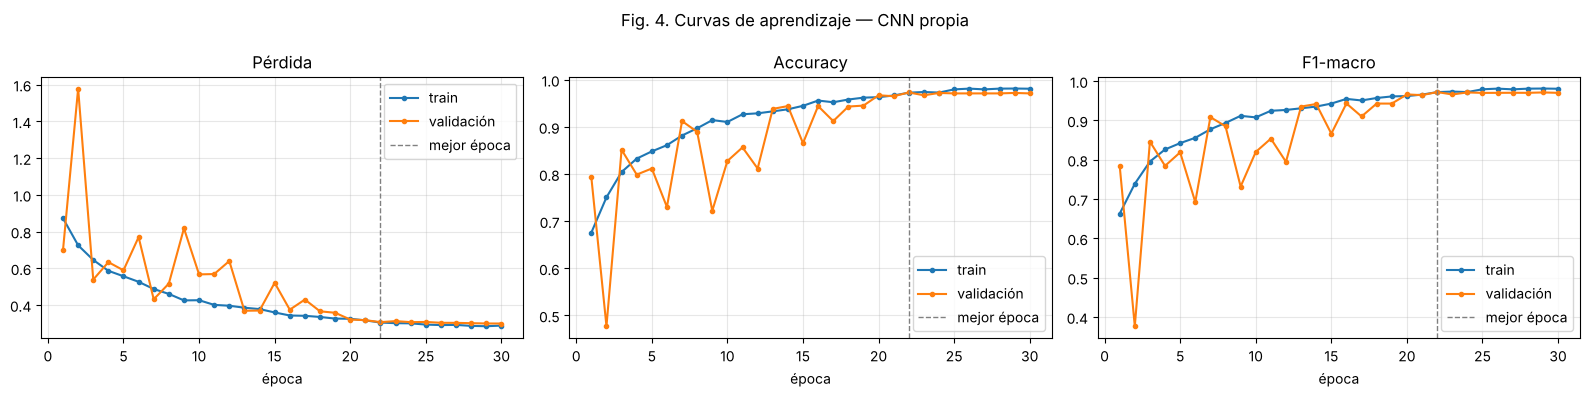

Mejor época: 22 | val acc 0.9731 | val F1 0.9720


In [11]:
def plot_history(h, title):
    best = h["val_f1"].idxmax()
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for ax, m, name in zip(axes, ["loss", "acc", "f1"], ["Pérdida", "Accuracy", "F1-macro"]):
        ax.plot(h["epoch"], h[f"train_{m}"], "o-", ms=3, label="train")
        ax.plot(h["epoch"], h[f"val_{m}"], "o-", ms=3, label="validación")
        ax.axvline(h.loc[best, "epoch"], color="gray", ls="--", lw=1, label="mejor época")
        ax.set_title(name); ax.set_xlabel("época"); ax.grid(alpha=.3); ax.legend()
    plt.suptitle(title); plt.tight_layout(); plt.show()
    print(f"Mejor época: {int(h.loc[best, 'epoch'])} | val acc {h.loc[best, 'val_acc']:.4f} | val F1 {h.loc[best, 'val_f1']:.4f}")

plot_history(hist_cnn, "Fig. 4. Curvas de aprendizaje — CNN propia")

## 6. Evaluación en el conjunto de prueba

Se evalúa **una sola vez** el checkpoint seleccionado en validación. Métricas:
- Accuracy y *balanced accuracy* (con IC 95 % por bootstrap, 1 000 remuestreos).
- Precision / recall / F1 por clase — en el contexto clínico el **recall** de cada tumor (y la tasa de tumores clasificados como sanos) es lo más relevante.
- Matriz de confusión y AUC ROC uno-contra-todos.

modelo                     CNN propia (desde cero)
accuracy                                  0.966102
acc_IC95                          [0.9541, 0.9761]
balanced_acc                              0.966282
f1_macro                                  0.965712
auc_ovr_macro                             0.994487
tumor→sano (FN clínico)                          5
tasa tumor→sano                              0.007

              precision    recall  f1-score   support

      glioma     0.9661    0.9870    0.9764       231
  meningioma     0.9370    0.9489    0.9429       235
   pituitary     0.9758    0.9641    0.9699       251
     healthy     0.9822    0.9650    0.9735       286

    accuracy                         0.9661      1003
   macro avg     0.9653    0.9663    0.9657      1003
weighted avg     0.9663    0.9661    0.9661      1003



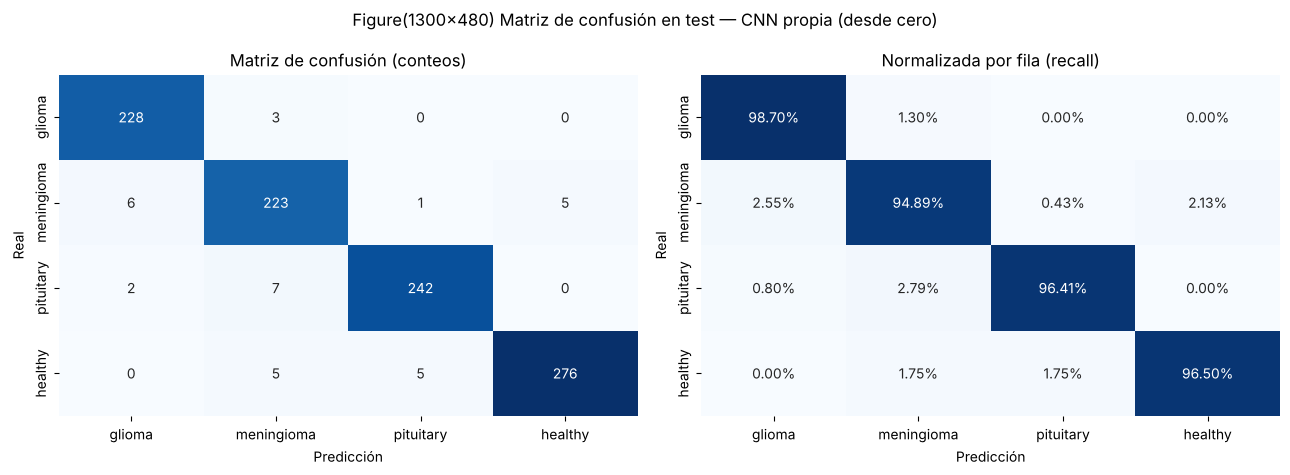

In [12]:
@torch.no_grad()
def predict(model, loader):
    model.eval(); P, Y = [], []
    for x, y in loader:
        P.append(F.softmax(model(x.to(DEVICE)), 1).cpu()); Y.append(y)
    return torch.cat(Y).numpy(), torch.cat(P).numpy()

def evaluate(model, loader, name, fig="Fig. 5."):
    y, p = predict(model, loader); yhat = p.argmax(1)
    rng = np.random.default_rng(0)
    boot = [accuracy_score(y[b], yhat[b]) for b in (rng.integers(0, len(y), len(y)) for _ in range(1000))]
    res = dict(modelo=name, accuracy=accuracy_score(y, yhat), acc_IC95=f"[{np.percentile(boot, 2.5):.4f}, {np.percentile(boot, 97.5):.4f}]",
               balanced_acc=balanced_accuracy_score(y, yhat), f1_macro=f1_score(y, yhat, average="macro"),
               auc_ovr_macro=roc_auc_score(y, p, multi_class="ovr"))
    tumor = y != CLASSES.index("healthy")
    res["tumor→sano (FN clínico)"] = int(((yhat == CLASSES.index("healthy")) & tumor).sum())
    res["tasa tumor→sano"] = round(res["tumor→sano (FN clínico)"] / int(tumor.sum()), 4)   # fracción de tumores no detectados
    print(pd.Series(res).to_string()); print()
    print(classification_report(y, yhat, target_names=CLASSES, digits=4))
    cm = confusion_matrix(y, yhat)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0], cbar=False)
    sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".2%", cmap="Blues", xticklabels=CLASSES,
                yticklabels=CLASSES, ax=axes[1], cbar=False)
    for ax, t in zip(axes, ["Matriz de confusión (conteos)", "Normalizada por fila (recall)"]):
        ax.set_xlabel("Predicción"); ax.set_ylabel("Real"); ax.set_title(t)
    plt.suptitle(f"{fig} Matriz de confusión en test — {name}"); plt.tight_layout(); plt.show()
    return res, y, p

model.load_state_dict(torch.load(MODELS / "mricnn_best.pt", map_location=DEVICE))
res_cnn, y_test, p_cnn = evaluate(model, loaders["test"], "CNN propia (desde cero)")
results = [res_cnn]

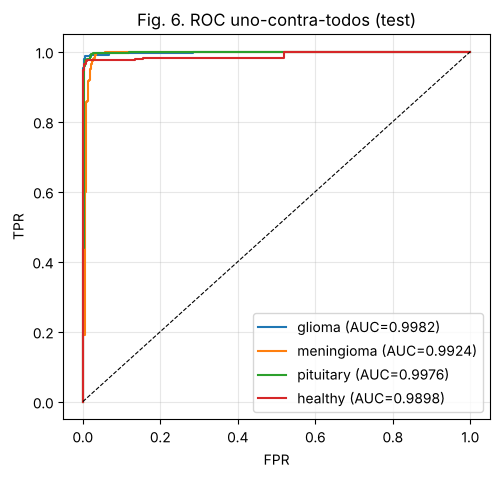

In [13]:
from sklearn.metrics import roc_curve
fig, ax = plt.subplots(figsize=(5.5, 5))
for k, c in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve(y_test == k, p_cnn[:, k])
    ax.plot(fpr, tpr, label=f"{c} (AUC={roc_auc_score(y_test == k, p_cnn[:, k]):.4f})")
ax.plot([0, 1], [0, 1], "k--", lw=.8); ax.set_xlabel("FPR"); ax.set_ylabel("TPR")
ax.set_title("Fig. 6. ROC uno-contra-todos (test)"); ax.legend(); ax.grid(alpha=.3); plt.show()

Errores en test: 34 de 1003


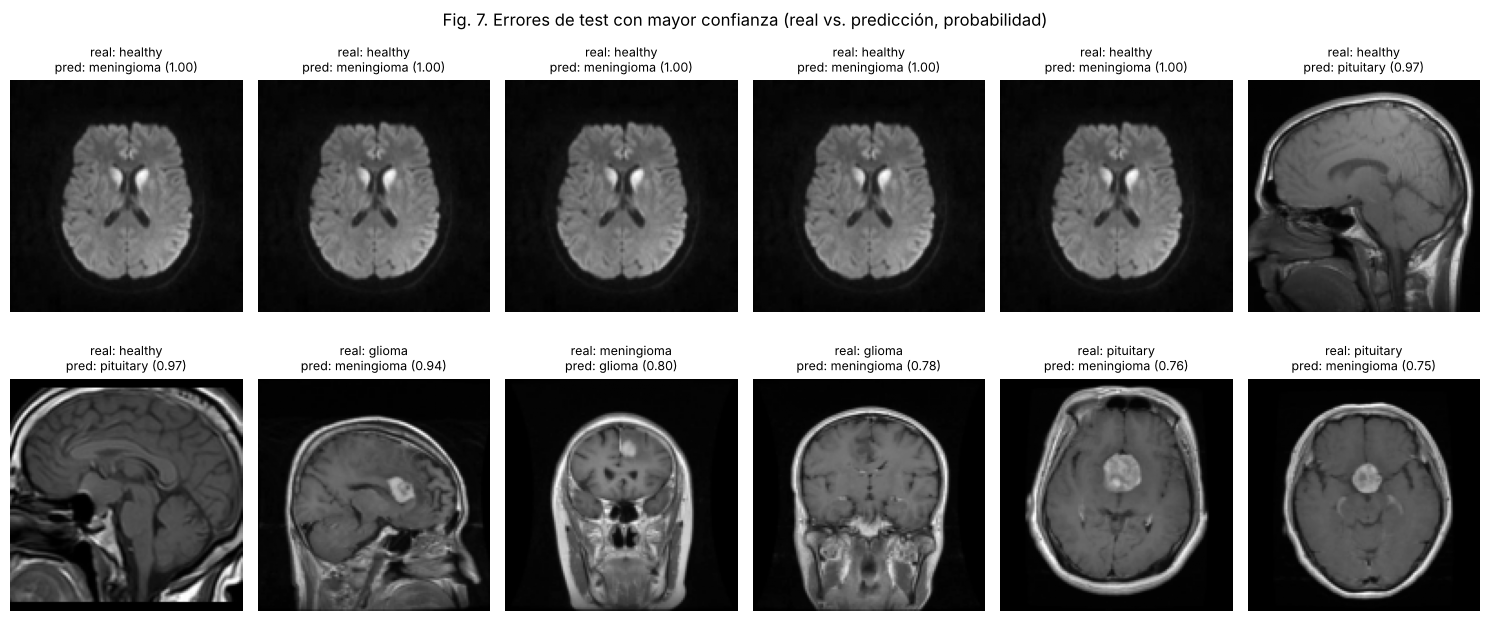

In [14]:
# Errores de clasificación en test
test_df = split.iloc[idx["test"]].reset_index(drop=True)
pred = p_cnn.argmax(1)
wrong = np.where(pred != y_test)[0]
print(f"Errores en test: {len(wrong)} de {len(y_test)}")
show = wrong[np.argsort(-p_cnn[wrong].max(1))][:12]      # los errores con mayor confianza
if len(show):
    fig, axes = plt.subplots(2, 6, figsize=(15, 6.6))
    for ax, i in zip(axes.ravel(), show):
        ax.imshow(X_all[idx["test"][i]], cmap="gray"); ax.axis("off")
        ax.set_title(f"real: {CLASSES[y_test[i]]}\npred: {CLASSES[pred[i]]} ({p_cnn[i].max():.2f})", fontsize=9)
    fig.suptitle("Fig. 7. Errores de test con mayor confianza (real vs. predicción, probabilidad)")
    for ax in axes.ravel()[len(show):]: ax.axis("off")
    plt.tight_layout(h_pad=2.5); plt.show()

glioma      aciertos: 228 | errores:  3
meningioma  aciertos: 223 | errores: 12
pituitary   aciertos: 242 | errores:  9
healthy     aciertos: 276 | errores: 10


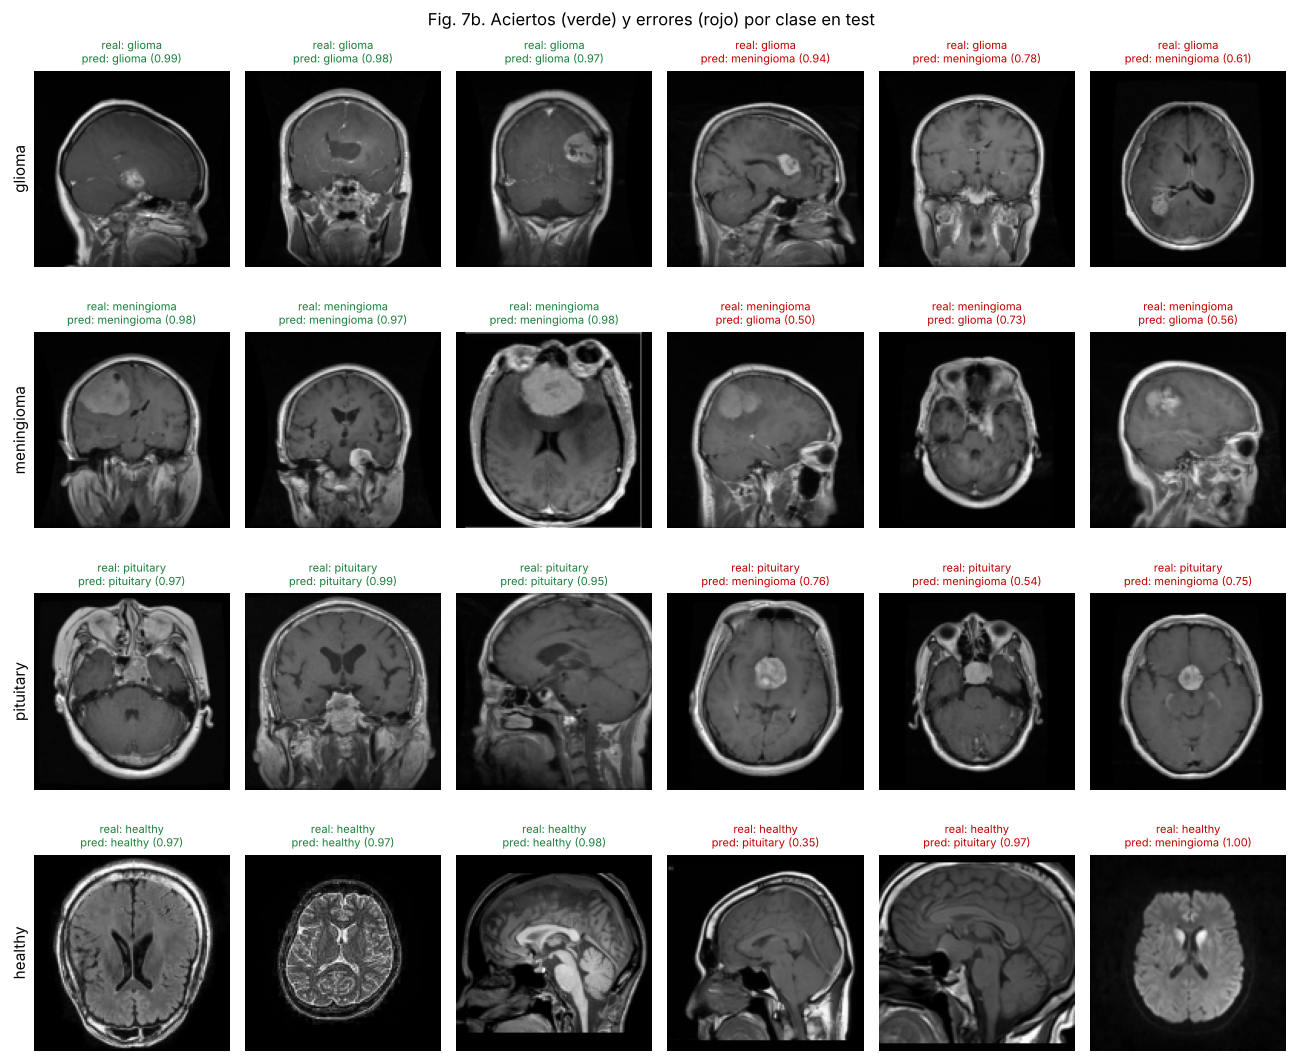

In [15]:
# Cuadrícula por clase: 3 aciertos (verde) y 3 errores (rojo) elegidos al azar, con clase predicha y probabilidad
rng_q = np.random.default_rng(CONFIG["seed"])
fig, axes = plt.subplots(len(CLASSES), 6, figsize=(13, 11))
for r_, c in enumerate(CLASSES):
    k = CLASSES.index(c)
    ok = np.where((y_test == k) & (pred == k))[0]; bad = np.where((y_test == k) & (pred != k))[0]
    pick = list(rng_q.choice(ok, min(3, len(ok)), replace=False)) + list(rng_q.choice(bad, min(3, len(bad)), replace=False))
    for j in range(6):
        ax = axes[r_, j]; ax.axis("off")
        if j < len(pick):
            i = pick[j]; hit = pred[i] == y_test[i]
            ax.imshow(X_all[idx["test"][i]], cmap="gray")
            ax.set_title(f"real: {c}\npred: {CLASSES[pred[i]]} ({p_cnn[i].max():.2f})", fontsize=8,
                         color="#1B7F3B" if hit else "#C00000")
    axes[r_, 0].text(-0.12, 0.5, c, transform=axes[r_, 0].transAxes, rotation=90, va="center", fontsize=11)
    print(f"{c:<11} aciertos: {len(ok):>3} | errores: {len(bad):>2}")
plt.suptitle("Fig. 7b. Aciertos (verde) y errores (rojo) por clase en test"); plt.tight_layout(h_pad=2.2); plt.show()

### Interpretabilidad: Grad-CAM

Grad-CAM [9] pondera los mapas de activación del último bloque convolucional por el gradiente de la clase predicha, mostrando **qué región** sustenta la decisión. Sirve para comprobar que el modelo mira la lesión/anatomía y no artefactos (bordes, texto, fondo).

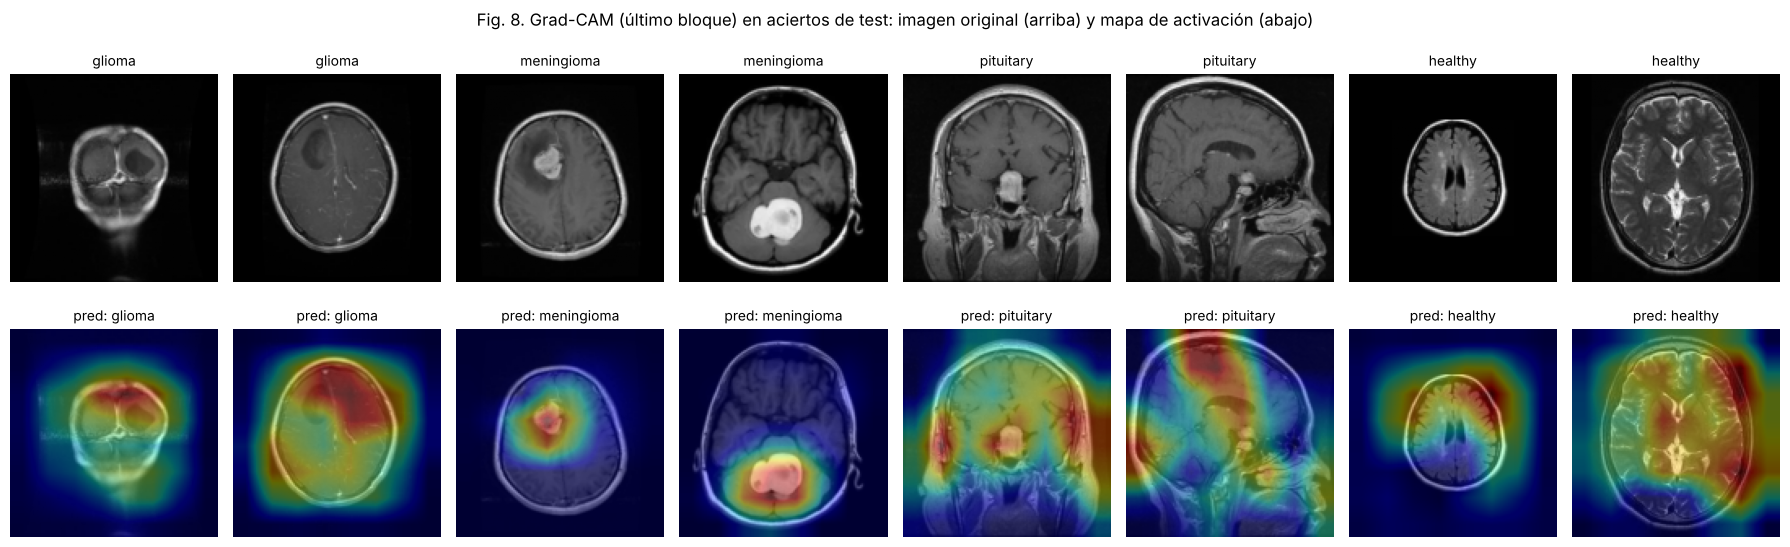

In [16]:
def grad_cam(model, x, target_layer):
    acts, grads = {}, {}
    def fwd_hook(m, i, o):
        acts["a"] = o
        o.register_hook(lambda g: grads.__setitem__("g", g))
    h = target_layer.register_forward_hook(fwd_hook)
    model.eval(); x = x.unsqueeze(0).to(DEVICE)
    logits = model(x); c = logits.argmax(1).item()
    model.zero_grad(); logits[0, c].backward()
    h.remove()
    w = grads["g"].mean((2, 3), keepdim=True)
    cam = F.relu((w * acts["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.detach().cpu().numpy(), c

ds_test = loaders["test"].dataset
rng = np.random.default_rng(1)
sel = [rng.choice(np.where((y_test == k) & (pred == k))[0]) for k in range(4) for _ in range(2)]
fig, axes = plt.subplots(2, 8, figsize=(18, 5.8))
for j, i in enumerate(sel):
    x, y = ds_test[i]
    cam, c = grad_cam(model, x, model.features[-1])
    img = X_all[idx["test"][i]]
    axes[0, j].imshow(img, cmap="gray"); axes[0, j].set_title(CLASSES[y], fontsize=10)
    axes[1, j].imshow(img, cmap="gray"); axes[1, j].imshow(cam, cmap="jet", alpha=.4)
    axes[1, j].set_title(f"pred: {CLASSES[c]}", fontsize=10)
for ax in axes.ravel(): ax.axis("off")
plt.suptitle("Fig. 8. Grad-CAM (último bloque) en aciertos de test: imagen original (arriba) y mapa de activación (abajo)"); plt.tight_layout(h_pad=2); plt.show()

## 7. Alternativa: fine-tuning de una red preentrenada (ResNet-18 [4], ImageNet)

El enunciado también permite usar una red existente con *fine-tuning*. Estrategia:
1. Entrada: la imagen en gris replicada a 3 canales y normalizada con la media/std de ImageNet.
2. **Etapa 1** (3 épocas): backbone congelado, sólo se entrena la nueva capa `fc` (4 clases).
3. **Etapa 2**: se descongela toda la red y se entrena con lr bajo (1e-4) para no destruir los filtros preentrenados.

Requiere descargar los pesos de ImageNet (`download.pytorch.org`). Si no hay acceso a internet, la celda **lo informa y no entrena** (no se reportan resultados que no se ejecutaron). Con `RUN_TRANSFER = False` se omite explícitamente.

In [17]:
RUN_TRANSFER = True

def get_resnet18():
    try:
        m = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
        return m
    except Exception as e:
        print(f"No fue posible descargar los pesos de ImageNet: {type(e).__name__}: {str(e)[:150]}")
        return None

resnet = get_resnet18() if RUN_TRANSFER else None
if resnet is None:
    print("→ Sección de transfer learning NO ejecutada en esta corrida. "
          "Ejecute el notebook con acceso a internet (o con los pesos en ~/.cache/torch) para obtener sus resultados.")
else:
    IMNET_MEAN, IMNET_STD = 0.449, 0.226            # media/std de ImageNet promediadas sobre RGB
    tl_loaders = make_loaders(n_channels=3, mean=IMNET_MEAN, std=IMNET_STD, bs=32)
    resnet.fc = nn.Linear(resnet.fc.in_features, 4)
    resnet = resnet.to(DEVICE)
    set_seed(CONFIG["seed"])
    for p in resnet.parameters(): p.requires_grad = False
    for p in resnet.fc.parameters(): p.requires_grad = True
    print("Etapa 1: sólo la capa fc")
    h1 = fit(resnet, tl_loaders, 3, 1e-3, MODELS / "resnet18_best.pt", params=resnet.fc.parameters(), patience=3)
    for p in resnet.parameters(): p.requires_grad = True
    print("Etapa 2: fine-tuning completo")
    h2 = fit(resnet, tl_loaders, 15, 1e-4, MODELS / "resnet18_best.pt", patience=5)
    plot_history(h2, "Fig. 10. Curvas de aprendizaje — ResNet-18 fine-tuning (etapa 2)")
    res_tl, _, p_tl = evaluate(resnet, tl_loaders["test"], "ResNet-18 fine-tuning", fig="Fig. 11.")
    results.append(res_tl)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


No fue posible descargar los pesos de ImageNet: URLError: <urlopen error Tunnel connection failed: 403 Forbidden>
→ Sección de transfer learning NO ejecutada en esta corrida. Ejecute el notebook con acceso a internet (o con los pesos en ~/.cache/torch) para obtener sus resultados.


## 7b. Experimentos comparativos

Para poder comparar resultados y medir su variabilidad se ejecutan dos experimentos con **la misma arquitectura e hiperparámetros** de las Secciones 4 y 5:

- **E1. Variabilidad entre semillas.** La CNN se entrena con 3 semillas (42, que es el modelo de la Sección 5; 7 y 123) sobre `split_grupos`. Se reporta media ± desviación estándar en test. La semilla cambia la inicialización, el orden de los lotes y la aumentación.
- **E2. Efecto de la fuga de datos.** La misma CNN se entrena con `split_aleatorio` (semilla 42) y se evalúa en su propio test. Ese test se separa en dos subconjuntos: imágenes **con** un (casi-)duplicado en train y imágenes **sin** él. Si el accuracy es mayor en el primer subconjunto, la partición aleatoria sobreestima el desempeño.

Cada corrida guarda sus resultados en `outputs/models/exp_*.json`. Si el archivo ya existe se carga en lugar de reentrenar, porque cada corrida tarda ~45 min en CPU.

In [18]:
RUN_EXPERIMENTS = True
EXP_SEEDS = [42, 7, 123]
pos = pd.Series(np.arange(len(split)), index=split["path"])      # path -> fila de X_all

def idx_from(df):
    return {s: pos[df.loc[df["split"] == s, "path"]].to_numpy() for s in ["train", "val", "test"]}

def loaders_for(idx_d, seed):
    mean, std = X_all[idx_d["train"]].mean() / 255.0, X_all[idx_d["train"]].std() / 255.0   # sólo train
    g = torch.Generator().manual_seed(seed)
    ds = {s: MRIDataset(X_all[idx_d[s]], y_all[idx_d[s]], train=(s == "train"), mean=mean, std=std) for s in idx_d}
    return {s: DataLoader(ds[s], batch_size=CONFIG["batch_size"], shuffle=(s == "train"),
                          generator=g if s == "train" else None) for s in ds}

def basic_metrics(y, p):
    yhat = p.argmax(1)
    return dict(accuracy=accuracy_score(y, yhat), balanced_acc=balanced_accuracy_score(y, yhat),
                f1_macro=f1_score(y, yhat, average="macro"), auc_ovr_macro=roc_auc_score(y, p, multi_class="ovr"))

def run_experiment(name, split_df, seed):
    f = MODELS / f"exp_{name}.json"
    if f.exists():
        print(f"[{name}] resultados cargados de {f.name}")
        return json.load(open(f))
    print(f"[{name}] entrenando (semilla {seed})")
    idx_d = idx_from(split_df)
    set_seed(seed); m = MRICNN().to(DEVICE)
    h = fit(m, loaders_for(idx_d, seed), CONFIG["epochs"], CONFIG["lr"], MODELS / f"exp_{name}.pt")
    y, p = predict(m, loaders_for(idx_d, seed)["test"])
    out = dict(name=name, seed=seed, best_epoch=int(h.loc[h["val_f1"].idxmax(), "epoch"]),
               val_f1=float(h["val_f1"].max()), **basic_metrics(y, p),
               test_paths=split_df.loc[split_df["split"] == "test", "path"].tolist(), y=y.tolist(), yhat=p.argmax(1).tolist())
    json.dump(out, open(f, "w"))
    return out

exps = {}
if RUN_EXPERIMENTS:
    # Semilla 42 en split_grupos = modelo de la Sección 5 (no se reentrena)
    exps["grupos_s42"] = dict(name="grupos_s42", seed=42, best_epoch=int(hist_cnn.loc[hist_cnn["val_f1"].idxmax(), "epoch"]),
                             val_f1=float(hist_cnn["val_f1"].max()), **basic_metrics(y_test, p_cnn))
    for sd in EXP_SEEDS[1:]:
        exps[f"grupos_s{sd}"] = run_experiment(f"grupos_s{sd}", splits["grupos"], sd)
    exps["aleatorio_s42"] = run_experiment("aleatorio_s42", splits["aleatorio"], 42)

[grupos_s7] resultados cargados de exp_grupos_s7.json
[grupos_s123] resultados cargados de exp_grupos_s123.json
[aleatorio_s42] resultados cargados de exp_aleatorio_s42.json


Tabla I. E1 — CNN propia en split_grupos, 3 semillas (test)


,seed,best_epoch,val_f1,accuracy,balanced_acc,f1_macro,auc_ovr_macro
0,42,22,0.9720,0.9661,0.9663,0.9657,0.9945
1,7,28,0.9793,0.9691,0.9689,0.9685,0.9938
2,123,29,0.9755,0.9781,0.9779,0.9778,0.9954


,media ± std
accuracy,0.9711 ± 0.0062
balanced_acc,0.9710 ± 0.0061
f1_macro,0.9707 ± 0.0063
auc_ovr_macro,0.9946 ± 0.0008


Métricas del modelo entrenado con split_aleatorio (su propio test): {'accuracy': 0.9781, 'balanced_acc': 0.9773, 'f1_macro': 0.9772, 'auc_ovr_macro': 0.9989} | mejor época: 27
Tabla II. E2 — efecto de la fuga de datos (accuracy en test)


,experimento,n_test,accuracy
0,"split_grupos (sin duplicados), media 3 semillas",1003,0.9711
1,split_aleatorio — test completo,1003,0.9781
2,split_aleatorio — test CON (casi-)duplicado en...,220,0.9909
3,split_aleatorio — test SIN duplicado en train,783,0.9745


Errores en el subconjunto con duplicado: 2 de 220 | sin duplicado: 20 de 783
Prueba exacta de Fisher (errores con vs. sin duplicado): p = 0.193
Tabla II-b. split_grupos: accuracy en test con dHash idéntico en train vs. resto


,semilla,acc_residual,n_residual,acc_resto,n_resto
0,42,1.0,55,0.9641,948
1,7,1.0,55,0.9673,948
2,123,1.0,55,0.9768,948


Media: residual 1.0000 | resto 0.9694


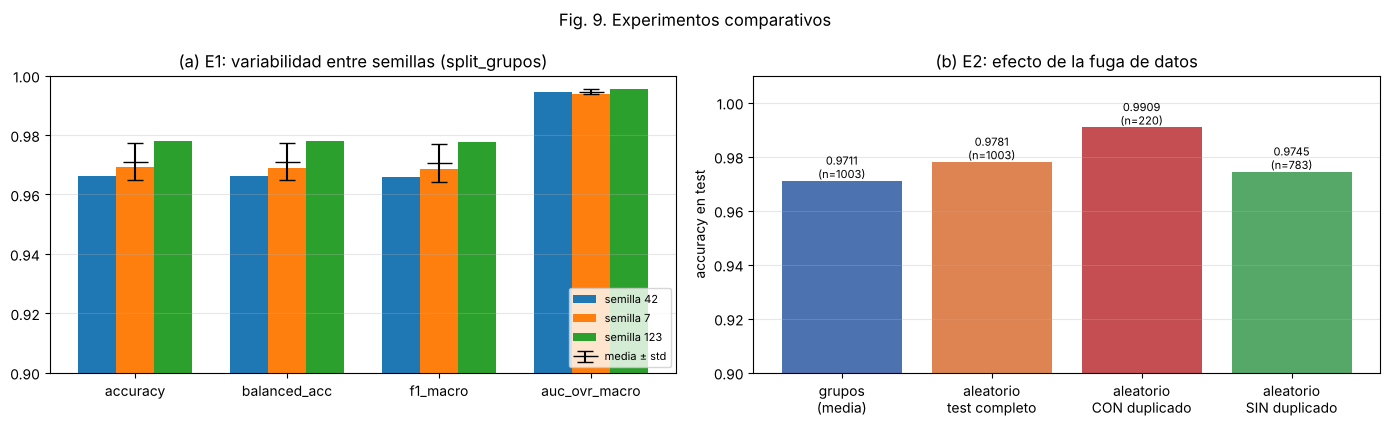

In [19]:
if RUN_EXPERIMENTS:
    cols = ["accuracy", "balanced_acc", "f1_macro", "auc_ovr_macro"]
    # E1: media ± desviación estándar entre semillas (split por grupos)
    e1 = pd.DataFrame([{k: exps[f"grupos_s{s}"][k] for k in ["seed", "best_epoch", "val_f1"] + cols} for s in EXP_SEEDS])
    print("Tabla I. E1 — CNN propia en split_grupos, 3 semillas (test)")
    display(e1.round(4))
    e1_summary = e1[cols].agg(["mean", "std"]).T
    display(e1_summary.assign(**{"media ± std": lambda d: d["mean"].map("{:.4f}".format) + " ± " + d["std"].map("{:.4f}".format)})[["media ± std"]])

    # E2: fuga de datos con split aleatorio
    ra = exps["aleatorio_s42"]
    sa = splits["aleatorio"]
    train_groups = set(sa.loc[sa["split"] == "train", "grupo"])
    grp = sa.set_index("path")["grupo"]
    leak = np.array([grp[p] in train_groups for p in ra["test_paths"]])
    ok = np.array(ra["y"]) == np.array(ra["yhat"])
    e2 = pd.DataFrame([
        dict(experimento="split_grupos (sin duplicados), media 3 semillas", n_test=len(y_test), accuracy=e1["accuracy"].mean()),
        dict(experimento="split_aleatorio — test completo", n_test=len(ok), accuracy=ok.mean()),
        dict(experimento="split_aleatorio — test CON (casi-)duplicado en train", n_test=int(leak.sum()), accuracy=ok[leak].mean()),
        dict(experimento="split_aleatorio — test SIN duplicado en train", n_test=int((~leak).sum()), accuracy=ok[~leak].mean()),
    ])
    print("Métricas del modelo entrenado con split_aleatorio (su propio test):",
          {k: round(ra[k], 4) for k in cols}, "| mejor época:", ra["best_epoch"])
    print("Tabla II. E2 — efecto de la fuga de datos (accuracy en test)")
    display(e2.round(4))
    print(f"Errores en el subconjunto con duplicado: {int((~ok[leak]).sum())} de {int(leak.sum())} | "
          f"sin duplicado: {int((~ok[~leak]).sum())} de {int((~leak).sum())}")
    from scipy.stats import fisher_exact
    tbl = [[int((~ok[leak]).sum()), int(ok[leak].sum())], [int((~ok[~leak]).sum()), int(ok[~leak].sum())]]
    print(f"Prueba exacta de Fisher (errores con vs. sin duplicado): p = {fisher_exact(tbl).pvalue:.3f}")

    # E2b: fuga residual en split_grupos (test con dHash idéntico en train), por semilla
    rows = []
    for sd in EXP_SEEDS:
        if sd == 42:
            paths, yy, yh = test_df["path"].tolist(), y_test, pred
        else:
            ex = exps[f"grupos_s{sd}"]; paths, yy, yh = ex["test_paths"], np.array(ex["y"]), np.array(ex["yhat"])
        res = np.array([p in RESIDUAL_TEST for p in paths]); okk = np.asarray(yy) == np.asarray(yh)
        rows.append(dict(semilla=sd, acc_residual=okk[res].mean(), n_residual=int(res.sum()),
                         acc_resto=okk[~res].mean(), n_resto=int((~res).sum())))
    e2b = pd.DataFrame(rows)
    print("Tabla II-b. split_grupos: accuracy en test con dHash idéntico en train vs. resto")
    display(e2b.round(4))
    print(f"Media: residual {e2b['acc_residual'].mean():.4f} | resto {e2b['acc_resto'].mean():.4f}")

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
    x = np.arange(len(cols))
    for j, s in enumerate(EXP_SEEDS):
        axes[0].bar(x + (j - 1) * 0.25, e1.loc[j, cols], 0.25, label=f"semilla {s}")
    axes[0].errorbar(x, e1_summary["mean"], yerr=e1_summary["std"], fmt="k_", ms=18, capsize=6, label="media ± std")
    axes[0].set_xticks(x, cols); axes[0].set_ylim(min(0.9, e1[cols].values.min() - 0.02), 1.0); axes[0].legend(fontsize=8, loc="lower right")
    axes[0].set_title("(a) E1: variabilidad entre semillas (split_grupos)"); axes[0].grid(axis="y", alpha=.3)
    labels = ["grupos\n(media)", "aleatorio\ntest completo", "aleatorio\nCON duplicado", "aleatorio\nSIN duplicado"]
    b = axes[1].bar(labels, e2["accuracy"], color=["#4C72B0", "#DD8452", "#C44E52", "#55A868"])
    axes[1].bar_label(b, labels=[f"{v:.4f}\n(n={n})" for v, n in zip(e2["accuracy"], e2["n_test"])], fontsize=8)
    axes[1].set_ylim(min(0.9, e2["accuracy"].min() - 0.03), 1.01); axes[1].set_ylabel("accuracy en test")
    axes[1].set_title("(b) E2: efecto de la fuga de datos"); axes[1].grid(axis="y", alpha=.3)
    plt.suptitle("Fig. 9. Experimentos comparativos"); plt.tight_layout(); plt.show()

In [20]:
summary = pd.DataFrame(results).set_index("modelo")
display(summary.round(4))
summary.to_csv(MODELS / "resultados_test.csv")

,accuracy,acc_IC95,balanced_acc,f1_macro,auc_ovr_macro,tumor→sano (FN clínico),tasa tumor→sano
modelo,,,,,,,
CNN propia (desde cero),0.9661,"[0.9541, 0.9761]",0.9663,0.9657,0.9945,5,0.007


## 7c. Figuras para el informe

Exporta, a partir de los resultados de este notebook, las figuras del informe de 2 páginas (`report/figs/`): aciertos y errores de test con Grad-CAM, la matriz de confusión normalizada y el experimento de fuga de datos. Los números del informe salen de las Tablas I–III y de la Sección 6.

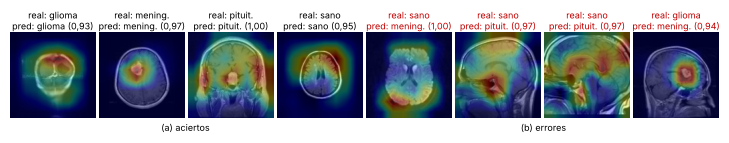

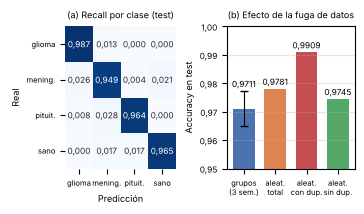

Figuras guardadas en report/figs | aciertos: [np.int64(108), np.int64(409), np.int64(474), np.int64(952)] | errores: [np.int64(894), np.int64(802), np.int64(911), np.int64(109)]


In [21]:
FIG_DIR = REPORT_FIGS
plt.rcParams.update({"font.size": 6.5, "axes.titlesize": 6.5, "axes.labelsize": 6.5, "xtick.labelsize": 6, "ytick.labelsize": 6})
coma = lambda v, d: f"{v:.{d}f}".replace(".", ",")      # coma decimal, como en el informe
ABBR = {"glioma": "glioma", "meningioma": "mening.", "pituitary": "pituit.", "healthy": "sano"}

# (1) Cualitativa: 4 aciertos (uno por clase) + 4 errores distintos (sin repetir grupo de casi-duplicados), con Grad-CAM
hits = [sel[2 * k] for k in range(4)]
order = wrong[np.argsort(-p_cnn[wrong].max(1))]
errs, used = [], set()
for i in order:
    g = test_df.loc[i, "grupo"]
    if g not in used:
        used.add(g); errs.append(i)
    if len(errs) == 4: break
fig, axes = plt.subplots(1, 8, figsize=(7.16, 1.3))
for ax, i, kind in zip(axes, hits + errs, ["ok"] * 4 + ["err"] * 4):
    x, _ = ds_test[i]
    cam, c = grad_cam(model, x, model.features[-1])
    ax.imshow(X_all[idx["test"][i]], cmap="gray"); ax.imshow(cam, cmap="jet", alpha=.35); ax.axis("off")
    ax.set_title(f"real: {ABBR[CLASSES[y_test[i]]]}\npred: {ABBR[CLASSES[c]]} ({coma(p_cnn[i].max(), 2)})",
                 color="black" if kind == "ok" else "#C00000", pad=2)
fig.text(0.25, 0.005, "(a) aciertos", ha="center"); fig.text(0.75, 0.005, "(b) errores", ha="center")
plt.subplots_adjust(left=0.005, right=0.995, top=0.80, bottom=0.07, wspace=0.04)
fig.savefig(FIG_DIR / "cualitativo.pdf"); fig.savefig(FIG_DIR / "cualitativo.png", dpi=300); plt.show()

# (2) Cuantitativa: matriz de confusión normalizada (semilla 42) + experimento de fuga (E2)
fig, (a, b) = plt.subplots(1, 2, figsize=(3.5, 2.0), gridspec_kw={"width_ratios": [1, 1.15]})
cmn = confusion_matrix(y_test, pred, normalize="true")
lab = [ABBR[c] for c in CLASSES]
sns.heatmap(cmn, annot=np.vectorize(lambda v: coma(v, 3))(cmn), fmt="", cmap="Blues", cbar=False,
            xticklabels=lab, yticklabels=lab, ax=a, annot_kws={"size": 6}, vmin=0, vmax=1)
a.set_xlabel("Predicción"); a.set_ylabel("Real"); a.set_title("(a) Recall por clase (test)")
a.tick_params(axis="x", rotation=0, labelsize=5.5); a.tick_params(axis="y", rotation=0, labelsize=5.5)
vals = [e1["accuracy"].mean()] + list(e2["accuracy"].iloc[1:])
bars = b.bar(["grupos\n(3 sem.)", "aleat.\ntotal", "aleat.\ncon dup.", "aleat.\nsin dup."], vals,
             color=["#4C72B0", "#DD8452", "#C44E52", "#55A868"], width=0.7)
b.errorbar(0, vals[0], yerr=e1["accuracy"].std(), fmt="none", ecolor="k", capsize=3, lw=0.8)
tops = [vals[0] + e1["accuracy"].std()] + vals[1:]
for k, (v, t) in enumerate(zip(vals, tops)):
    b.text(k, t + 0.0007, coma(v, 4), ha="center", va="bottom", fontsize=6)
b.set_ylim(0.95, 1.0); b.set_ylabel("Accuracy en test"); b.set_title("(b) Efecto de la fuga de datos")
b.grid(axis="y", alpha=.3); b.tick_params(axis="x", labelsize=5.5)
b.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: coma(v, 2)))
plt.tight_layout(pad=0.3, w_pad=0.8)
fig.savefig(FIG_DIR / "cuantitativo.pdf"); fig.savefig(FIG_DIR / "cuantitativo.png", dpi=300); plt.show()
plt.rcParams.update(plt.rcParamsDefault)
print("Figuras guardadas en", FIG_DIR.relative_to(ROOT), "| aciertos:", hits, "| errores:", errs)

## 7d. Resumen de cifras para el informe

Reúne en un solo lugar (y en `outputs/models/resumen_informe.json`) las cifras que se citan en el informe, para que ambos documentos coincidan.

In [22]:
resumen = {
    "dataset": {"imagenes": int(len(inv)), "por_clase": inv["clase"].value_counts().reindex(CLASSES).to_dict(),
                "cortes_unicos": int(inv["grupo"].nunique()),
                "redundancia_%": red["% redundante"].to_dict(),
                "resolucion_mediana_wxh": {c: f"{int(red.loc[c, 'ancho_mediana'])}x{int(red.loc[c, 'alto_mediana'])}" for c in CLASSES},
                "intensidad_media": red["intensidad_media"].round(1).to_dict()},
    "particion_grupos": {s_: int((split["split"] == s_).sum()) for s_ in ["train", "val", "test"]},
    "fuga_residual_test": len(RESIDUAL_TEST),
    "cnn_semilla_42_test": {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else v) for k, v in res_cnn.items() if k != "modelo"},
    "cnn_3_semillas_test": {m: f"{e1_summary.loc[m, 'mean']:.4f} ± {e1_summary.loc[m, 'std']:.4f}" for m in e1_summary.index},
    "fuga_split_aleatorio": e2.set_index("experimento")["accuracy"].round(4).to_dict(),
    "fuga_residual_split_grupos": {"acc_residual_media": round(float(e2b["acc_residual"].mean()), 4),
                                   "acc_resto_media": round(float(e2b["acc_resto"].mean()), 4)},
}
(MODELS / "resumen_informe.json").write_text(json.dumps(resumen, indent=1, ensure_ascii=False, default=str), encoding="utf-8")
print(json.dumps(resumen, indent=1, ensure_ascii=False, default=str))

{
 "dataset": {
  "imagenes": 7023,
  "por_clase": {
   "glioma": 1621,
   "meningioma": 1645,
   "pituitary": 1757,
   "healthy": 2000
  },
  "cortes_unicos": 5835,
  "redundancia_%": {
   "glioma": 0.2,
   "meningioma": 7.3,
   "pituitary": 1.3,
   "healthy": 52.2
  },
  "resolucion_mediana_wxh": {
   "glioma": "512x512",
   "meningioma": "512x512",
   "pituitary": "512x512",
   "healthy": "232x243"
  },
  "intensidad_media": {
   "glioma": 33.0,
   "meningioma": 45.1,
   "pituitary": 49.0,
   "healthy": 60.4
  }
 },
 "particion_grupos": {
  "train": 5016,
  "val": 1004,
  "test": 1003
 },
 "fuga_residual_test": 55,
 "cnn_semilla_42_test": {
  "accuracy": 0.9661,
  "acc_IC95": "[0.9541, 0.9761]",
  "balanced_acc": 0.9663,
  "f1_macro": 0.9657,
  "auc_ovr_macro": 0.9945,
  "tumor→sano (FN clínico)": 5,
  "tasa tumor→sano": 0.007
 },
 "cnn_3_semillas_test": {
  "accuracy": "0.9711 ± 0.0062",
  "balanced_acc": "0.9710 ± 0.0061",
  "f1_macro": "0.9707 ± 0.0063",
  "auc_ovr_macro": "0.994

## 8. Resultados y discusión

*(Escrito a partir de las salidas de este notebook. El entrenamiento se ejecutó en CPU de 2 núcleos: 43 min la corrida principal y ~58–60 min cada corrida de la Sección 7b.)*

### 8.1 Resultados cuantitativos

**Tabla III.** Resultados en test (1 003 imágenes, `split_grupos`, sin duplicados entre particiones). La fila "media ± std" resume las 3 semillas de E1 (Tabla I).

| Modelo | Accuracy | Balanced acc. | F1-macro | AUC OvR | Tumor → sano |
|---|---|---|---|---|---|
| CNN propia, semilla 42 (Secciones 5 y 6) | 0,9661 (IC 95 %: 0,954–0,976) | 0,9663 | 0,9657 | 0,9945 | 5 / 717 |
| CNN propia, 3 semillas (media ± std) | **0,9711 ± 0,0062** | 0,9710 ± 0,0061 | 0,9707 ± 0,0063 | 0,9946 ± 0,0008 | — |
| ResNet-18 fine-tuning (Sección 7) | no ejecutado (sin acceso a los pesos de ImageNet) | | | | |

Por clase (semilla 42, Fig. 5), el recall es glioma 0,987, meningioma 0,949, pituitary 0,964 y healthy 0,965. Los 5 falsos negativos clínicos (tumor clasificado como sano) son todos meningiomas.

**Efecto de la fuga de datos (Tabla II, Fig. 9b).** Con `split_aleatorio`, la misma CNN obtiene 0,9781 en su test, por encima de la media con `split_grupos` (0,9711). Dentro de ese test, las 220 imágenes que tienen un (casi-)duplicado en train alcanzan 0,9909 (2 errores), frente a 0,9745 (20 errores) de las 783 sin duplicado.

### 8.2 Análisis

**Capacidad y sobreajuste.** Con ~0,3 M parámetros, la red tiene capacidad suficiente: el accuracy de train llega a 0,98. La brecha train–validación al final es de ~1 punto (Fig. 4), así que el modelo se ubica cerca del equilibrio sesgo-varianza [15]. Contribuyen la regularización explícita (weight decay, dropout, label smoothing [12]), la implícita (aumentación de datos) y el diseño con Global Average Pooling [11], que evita las capas densas que concentran la mayoría de los parámetros en arquitecturas tipo VGG [2].

**Dinámica de entrenamiento.** La validación oscila con fuerza en las primeras ~12 épocas (F1 de 0,38 en la época 2, Fig. 4) y se estabiliza cuando el *cosine annealing* [14] reduce la tasa de aprendizaje. Esto es compatible con dos efectos: (i) con lr alto el modelo salta entre mínimos, y (ii) las estadísticas de BatchNorm [3] se estiman sobre lotes aumentados, por lo que las de inferencia aún no son representativas. Las tres semillas eligen su mejor época al final (22, 28 y 29). Esto indica que el término del *schedule*, más que el early stopping, determina el modelo final.

**Variabilidad.** La desviación estándar entre semillas (0,6 pp de accuracy) es comparable al ancho del IC bootstrap de una sola corrida (±1,1 pp). Por tanto, diferencias menores a ~1 punto entre configuraciones no deben interpretarse como mejoras reales sin repetir experimentos. El AUC es mucho más estable (±0,0008): el ordenamiento de probabilidades es consistente entre semillas, y la variación se concentra en ejemplos cercanos a la frontera de decisión.

**Comparación con la literatura.** El accuracy obtenido (97,1 % ± 0,6) está en el mismo rango que el 96,56 % de Badža y Barjaktarović [6] con una CNN propia. La comparación es solo indicativa: [6] usa 3 clases de figshare [5] y validación cruzada a nivel de registro, mientras que aquí hay 4 clases y una partición que excluye casi-duplicados.

**Fuga de datos.** La dirección del efecto coincide con Yagis *et al.* [7]: las imágenes con un casi-duplicado en entrenamiento se clasifican casi perfectamente (99,1 %). La magnitud es mucho menor que la reportada allí (hasta 55 pp), por dos razones: solo el 22 % del test aleatorio está "contaminado", y el dataset no contiene volúmenes completos sino cortes ya seleccionados. Además, la diferencia entre subconjuntos (2/220 frente a 20/783 errores) no es estadísticamente significativa con este tamaño de muestra (prueba exacta de Fisher, p = 0,19). La conclusión prudente es que la partición aleatoria **sesga al alza** la estimación (+0,7 pp en el test completo y +1,6 pp en el subconjunto contaminado), pero en este dataset el sesgo es moderado. Aun así, la partición por grupos es la metodológicamente correcta.

**Redundancia y fuga residual en `split_grupos` (Secciones 1b y 2, Tabla II-b).** La redundancia está muy concentrada: el 52,2 % de las imágenes `healthy` son copias de otro corte (957 cortes únicos de 2 000), frente a 0,2–7,3 % en las clases tumorales. Además, el 5,5 % de las imágenes de test (55) comparte un dHash idéntico con alguna imagen de train. No son copias, porque su correlación con el par más parecido es como máximo 0,942, por debajo del umbral de 0,95, pero sí cortes muy parecidos, probablemente del mismo paciente. Las tres semillas aciertan el **100 %** de esas 55 imágenes, frente a un 0,9694 de media en las 948 restantes. Por tanto, aun sin duplicados, existe una fuga a nivel de paciente que infla ligeramente las métricas, unos 0,2 puntos sobre el total (0,9711 frente a 0,9694). Este hallazgo refuerza la advertencia de Yagis *et al.* [7].

**Errores (Fig. 7).** La clase más difícil es meningioma (recall 0,949, F1 0,943). Es la que más se confunde en ambas direcciones: con glioma, cuando la lesión es intraaxial o heterogénea, y con pituitary, cuando está en la línea media cerca de la región selar, como en los dos pituitary clasificados como meningioma de la Fig. 7. Los 5 errores de mayor confianza son copias casi idénticas de **una misma** imagen sana (DWI axial) predicha como meningioma con probabilidad ≈1,00 (Fig. 7). Como el split agrupa duplicados, el grupo completo cayó en test, así que el número efectivo de casos distintos mal clasificados es menor que 34.

**Interpretabilidad y posible atajo (Fig. 8, Fig. 1, Fig. 1b, Tabla 0).** En glioma y meningioma, Grad-CAM [9] se concentra sobre la lesión, lo que indica que la red usa evidencia anatómicamente plausible. En algunas imágenes sanas y pituitary la activación es difusa o periférica. Por otro lado, la clase `healthy` tiene condiciones de adquisición distintas, medidas en la Tabla 0: resolución mediana de 232×243 px frente a 512×512 en las tres clases tumorales (solo el 1 % de las sanas es de 512×512), intensidad media de 60,4 frente a 33,0–49,0, y un 69 % de imágenes no cuadradas frente a 0–13 %. Visualmente también predominan secuencias T2/FLAIR/DWI axiales, frente a T1 con contraste en los tumores; esta última observación no está cuantificada. Todo esto es coherente con su procedencia: según la descripción de la compilación original, la clase sin tumor proviene de Br35H [10]. Además, el relleno con negro (Sección 3) añade bordes sobre todo a imágenes sanas, porque son las no cuadradas; estirarlas, como alternativa, las deformaría. Ambas opciones dejan una señal ligada a la clase. Es un escenario típico de *shortcut learning* [8]: parte de la separación sano/tumor podría deberse a la secuencia o fuente y no a la patología. El error de alta confianza sobre una DWI sana sugiere que el modelo no generaliza bien a secuencias poco representadas en su clase.

### 8.3 Limitaciones
- Clasificación de cortes 2D aislados, sin contexto volumétrico.
- Sin identificador de paciente: la partición por grupos elimina duplicados, pero no garantiza la separación por paciente. El 5,5 % del test tiene un corte casi idéntico en train y se clasifica sin errores, por lo que las métricas son ligeramente optimistas [7].
- Posible sesgo de fuente en la clase `healthy`: resolución, intensidad y relación de aspecto distintas (Tabla 0). Su efecto sobre el modelo no se puede aislar sin un conjunto externo.
- Resolución reducida (128 px) por restricciones de cómputo. Las lesiones pequeñas pueden perder detalle.
- Solo 3 semillas para la variabilidad y una sola corrida para la comparación de particiones.
- La comparación con transfer learning no se ejecutó en este entorno.

### 8.4 Mejoras propuestas (basadas en los resultados)
1. **Ejecutar la Sección 7 (ResNet-18 preentrenada [4])** y compararla con la Tabla III. Las características de ImageNet suelen ayudar con pocos datos, lo que podría reducir los errores entre meningioma y glioma.
2. **Controlar el atajo de secuencia:** normalizar intensidades por imagen (p. ej. z-score o ecualización de histograma), aumentar el contraste más agresivamente y evaluar en un conjunto externo o estratificado por secuencia y plano.
3. **Mayor resolución (224 px)** y más canales con GPU, para mejorar la clase meningioma, cuyas confusiones dependen de detalles finos de localización y bordes.
4. **Calibración y umbral clínico:** ajustar el umbral de la clase `healthy` para minimizar los falsos negativos tumor → sano, aunque aumenten los falsos positivos.
5. **Más semillas o validación cruzada por grupos** para estrechar los intervalos y probar la significancia de las diferencias.

## 9. Lista de comprobación de requisitos

| Requisito | Estado | Dónde |
|---|---|---|
| Pipeline para cargar las imágenes | Ejecutado | Sección 3 (`load_image`, `build_cache`, `MRIDataset`, `make_loaders`) |
| División en entrenamiento y prueba (más validación) | Ejecutado | Sección 2: 5 016 / 1 004 / 1 003, estratificado |
| Evitar fuga de datos | Cumplido: sin duplicados entre particiones. Parcial: fuga residual por paciente, cuantificada | Sección 2 (0 grupos y 0 md5 compartidos; 5,5 % del test con dHash idéntico en train), Sección 7b E2 y Tabla II-b; normalización sólo con train; test usado una vez por modelo |
| Análisis de duplicados (criterio reconstruido y verificado) y diferencias de adquisición por clase | Ejecutado | Sección 1b (Tabla 0, Fig. 1b) |
| Arquitectura CNN con bloques convolución + max pooling | Ejecutado | Sección 4 `MRICNN` |
| Clasificación en las 4 categorías | Ejecutado | Sección 6, métricas por clase |
| Alternativa con red existente + fine-tuning | Parcial: implementado, **no ejecutado** aquí (sin acceso a los pesos) | Sección 7 |
| Comparación entre experimentos y medidas estadísticas | Ejecutado | Sección 7b (Tablas I–II, Fig. 9), IC bootstrap en la Sección 6 |
| Reproducibilidad (semillas, configuración, versiones) | Cumplido | Sección 0 `CONFIG`, `set_seed`; splits versionados; `outputs/models/exp_*.json` |
| Referencias en formato IEEE citadas en el texto | Cumplido | Introducción y Secciones 2, 4, 5, 7 y 8; lista en la Sección 10 |

**Nota sobre la ejecución.** La celda de entrenamiento de la Sección 5 muestra la salida de su ejecución completa (30 épocas). Las corridas de la Sección 7b se entrenaron con la función `run_experiment` de este notebook y sus resultados quedaron en `outputs/models/exp_*.json`, que la celda carga si existen. Con `RETRAIN = True` y borrando esos archivos, el notebook reentrena todo desde cero (~4 h en CPU; mucho menos con GPU o MPS).

**Artefactos:** `outputs/models/mricnn_best.pt`, `outputs/models/mricnn_history.csv`, `outputs/models/exp_*.json` / `.pt`, `outputs/models/resultados_test.csv`, `data/cache/gray_128_*.npy` (caché regenerable).

## 10. Referencias

[1] D. N. Louis *et al.*, "The 2021 WHO classification of tumors of the central nervous system: A summary," *Neuro-Oncology*, vol. 23, no. 8, pp. 1231–1251, 2021, doi: 10.1093/neuonc/noab106.

[2] K. Simonyan and A. Zisserman, "Very deep convolutional networks for large-scale image recognition," in *Proc. Int. Conf. Learn. Represent. (ICLR)*, 2015, arXiv:1409.1556.

[3] S. Ioffe and C. Szegedy, "Batch normalization: Accelerating deep network training by reducing internal covariate shift," in *Proc. Int. Conf. Mach. Learn. (ICML)*, 2015, pp. 448–456.

[4] K. He, X. Zhang, S. Ren, and J. Sun, "Deep residual learning for image recognition," in *Proc. IEEE Conf. Comput. Vis. Pattern Recognit. (CVPR)*, 2016, pp. 770–778.

[5] J. Cheng *et al.*, "Enhanced performance of brain tumor classification via tumor region augmentation and partition," *PLoS ONE*, vol. 10, no. 10, Art. no. e0140381, 2015, doi: 10.1371/journal.pone.0140381.

[6] M. M. Badža and M. Č. Barjaktarović, "Classification of brain tumors from MRI images using a convolutional neural network," *Appl. Sci.*, vol. 10, no. 6, Art. no. 1999, 2020, doi: 10.3390/app10061999.

[7] E. Yagis *et al.*, "Effect of data leakage in brain MRI classification using 2D convolutional neural networks," *Sci. Rep.*, vol. 11, 2021, doi: 10.1038/s41598-021-01681-w.

[8] R. Geirhos *et al.*, "Shortcut learning in deep neural networks," *Nat. Mach. Intell.*, vol. 2, no. 11, pp. 665–673, 2020, doi: 10.1038/s42256-020-00257-z.

[9] R. R. Selvaraju, M. Cogswell, A. Das, R. Vedantam, D. Parikh, and D. Batra, "Grad-CAM: Visual explanations from deep networks via gradient-based localization," in *Proc. IEEE Int. Conf. Comput. Vis. (ICCV)*, 2017, pp. 618–626.

[10] J. Chaki, "Brain tumor MRI dataset," IEEE DataPort, doi: 10.21227/1jny-g144. Versión usada: "Brain Tumor (MRI Scans)," Kaggle (rm1000). [Online]. Available: https://www.kaggle.com/datasets/rm1000/brain-tumor-mri-scans

[11] M. Lin, Q. Chen, and S. Yan, "Network in network," in *Proc. Int. Conf. Learn. Represent. (ICLR)*, 2014, arXiv:1312.4400.

[12] C. Szegedy, V. Vanhoucke, S. Ioffe, J. Shlens, and Z. Wojna, "Rethinking the inception architecture for computer vision," in *Proc. IEEE Conf. Comput. Vis. Pattern Recognit. (CVPR)*, 2016, pp. 2818–2826.

[13] I. Loshchilov and F. Hutter, "Decoupled weight decay regularization," in *Proc. Int. Conf. Learn. Represent. (ICLR)*, 2019, arXiv:1711.05101.

[14] I. Loshchilov and F. Hutter, "SGDR: Stochastic gradient descent with warm restarts," in *Proc. Int. Conf. Learn. Represent. (ICLR)*, 2017, arXiv:1608.03983.

[15] I. Goodfellow, Y. Bengio, and A. Courville, *Deep Learning*. Cambridge, MA, USA: MIT Press, 2016.